# NeurIPS 2021 BMMC multiome (s1d1 + s1d3): preprocessing, clustering and annotation

Bone marrow mononuclear cells from site 1, donors 1 and 3 (GSE194122, Luecken et al.), processed exactly as
`pbmc_v3.ipynb`, so models trained on the PBMC data can be tested on them. The inputs are:

- **GEX:** the Cell Ranger ARC `filtered_feature_bc_matrix.h5` rebuilt from each sample's GEX BAM, because no
  multiome `.h5` is public (`jobs/06_rebuild_gex.sbatch`). The rebuild reproduces our PBMC `.h5` exactly.
- **ATAC:** Cell Ranger ARC's own fragment files (S3).
- **Combination:** the two samples combined `aggr`-style, with barcode suffix `-1` = s1d1 and `-2` = s1d3
  (`jobs/07_bmmc_aggr.sbatch`).

Differences from `pbmc_v3`, all because there are two samples or no peak matrix:

- Scrublet runs per sample, with each sample's own expected doublet rate.
- AMULET is read per GEM well (`batch_1`, `batch_2`).
- No ATAC peak matrix is public, so only `rna_annotated.h5ad` is saved; ATAC analyses use the fragment files instead.

---

The rest follows `pbmc_v3`.

Follows the scanpy [preprocessing and clustering tutorial](https://scanpy.readthedocs.io/en/stable/tutorials/basics/clustering.html),
with ATAC quality control added: fragment counts, TSS enrichment (TSSE), nucleosome signal
and AMULET multiplets. A cell is kept only if it passes both the RNA and the ATAC checks.

**Pipeline**

1. QC metrics for both modalities.
2. **Light filter:** remove barcodes that aren't usable cells (fewer than 100 genes or 1,000 ATAC
   fragments), then genes detected in fewer than 3 cells.
3. **Doublet detection** (Scrublet and AMULET): cells are flagged, not yet removed.
4. **Exploratory clustering** of the light-filtered cells.
5. **Re-assess QC** on those clusters.
6. **First filtering:** remove low-quality cells and doublets, with no upper limits on RNA counts or
   ATAC fragments (very high values are left to the doublet detectors). Re-plot QC and re-cluster the
   remaining cells, then **final filtering** adds upper limits on RNA counts and ATAC fragments to remove
   remaining potential doublets, and drops genes detected in fewer than 3 of the final cells.
7. **Final clustering** of the filtered cells, then **cell-type annotation with Azimuth**.

Doublet scores depend only on the fixed light filter, so the thresholds in step 6 can be changed without
redoing doublet detection.

In [1]:
import collections
import os
import re
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
from matplotlib.collections import PathCollection
from matplotlib.figure import Figure

# rpy2 finds R through R_HOME, which the Jupyter kernel doesn't set (it doesn't activate the env)
os.environ.setdefault("R_HOME", os.path.join(sys.prefix, "lib", "R"))
from azimuthpy import annotate_adata_azimuth  # loads Seurat and Azimuth in R

sc.set_figure_params(dpi=300, facecolor="white")
# every figure shown is also saved to figures/<notebook>/<In[] number>_<n>_<title>.svg; point clouds are
# rasterised at 300 dpi inside it, text and axes stay vector (and text editable)
svg_dir = Path.cwd().parent / "figures" / "bmmc_s1d1_s1d3_v3"
svg_dir.mkdir(parents=True, exist_ok=True)
plt.rcParams["svg.fonttype"] = "none"
png_formatter = get_ipython().display_formatter.formatters["image/png"]
show_png = png_formatter.lookup_by_type(Figure)
figs_in_cell = collections.Counter()


def save_svg_and_show(fig):
    cell = get_ipython().execution_count
    figs_in_cell[cell] += 1
    labels = [ax.get_title() or ax.get_ylabel() for ax in fig.axes]
    title = re.sub(r"\W+", "_", next((label for label in labels if label), "figure")).strip("_")[:40]
    for points in fig.findobj(PathCollection):
        if len(points.get_offsets()) > 1000:
            points.set_rasterized(True)
    fig.savefig(svg_dir / f"{cell:03d}_{figs_in_cell[cell]}_{title}.svg", dpi=300, bbox_inches="tight")
    return show_png(fig)


png_formatter.for_type(Figure, save_svg_and_show)

DATA = Path.cwd().parent / "data"
SAMPLE = "bmmc_s1d1_s1d3"
SAMPLES = {"1": "s1d1", "2": "s1d3"}  # GEM-well suffix -> sample
h5_file = DATA / "raw" / "bmmc" / f"{SAMPLE}_filtered_feature_bc_matrix.h5"
atac_metrics_file = DATA / "processed" / "bmmc" / "atac_metrics.tsv"
amulet_files = [DATA / "processed" / "bmmc" / "amulet" / f"batch_{well}" / "MultipletProbabilities.txt" for well in SAMPLES]
out_dir = DATA / "processed" / "bmmc"
azimuth_ref = DATA / "reference" / "azimuth" / "human_pbmc"


    an issue that caused a segfault when used with rpy2:
    https://github.com/rstudio/reticulate/pull/1188
    Make sure that you use a version of that package that includes
    the fix.
    

## Data loading

The rebuilt file holds gene expression only (no peaks). Each cell's sample comes from its barcode suffix.

In [2]:
adata = sc.read_10x_h5(h5_file)
adata.var_names_make_unique()
adata.obs["sample"] = pd.Categorical(adata.obs_names.str.rsplit("-", n=1).str[1].map(SAMPLES))
print(adata.obs["sample"].value_counts().to_string())
adata

/gpfs/scratch/qp252877/anaconda/envs/azimuth/lib/python3.10/site-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/gpfs/scratch/qp252877/anaconda/envs/azimuth/lib/python3.10/site-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


sample
s1d1    8442
s1d3    5626


AnnData object with n_obs × n_vars = 14068 × 36601
    obs: 'sample'
    var: 'gene_ids', 'feature_types', 'genome', 'interval'

## Quality control metrics

### RNA

In [3]:
# mitochondrial genes, "MT-" for human
adata.var["mt"] = adata.var_names.str.startswith("MT-")
# ribosomal genes
adata.var["ribo"] = adata.var_names.str.startswith(("RPS", "RPL"))
# hemoglobin genes
adata.var["hb"] = adata.var_names.str.contains("^HB[^(P)]")

sc.pp.calculate_qc_metrics(adata, qc_vars=["mt", "ribo", "hb"], inplace=True, log1p=True)

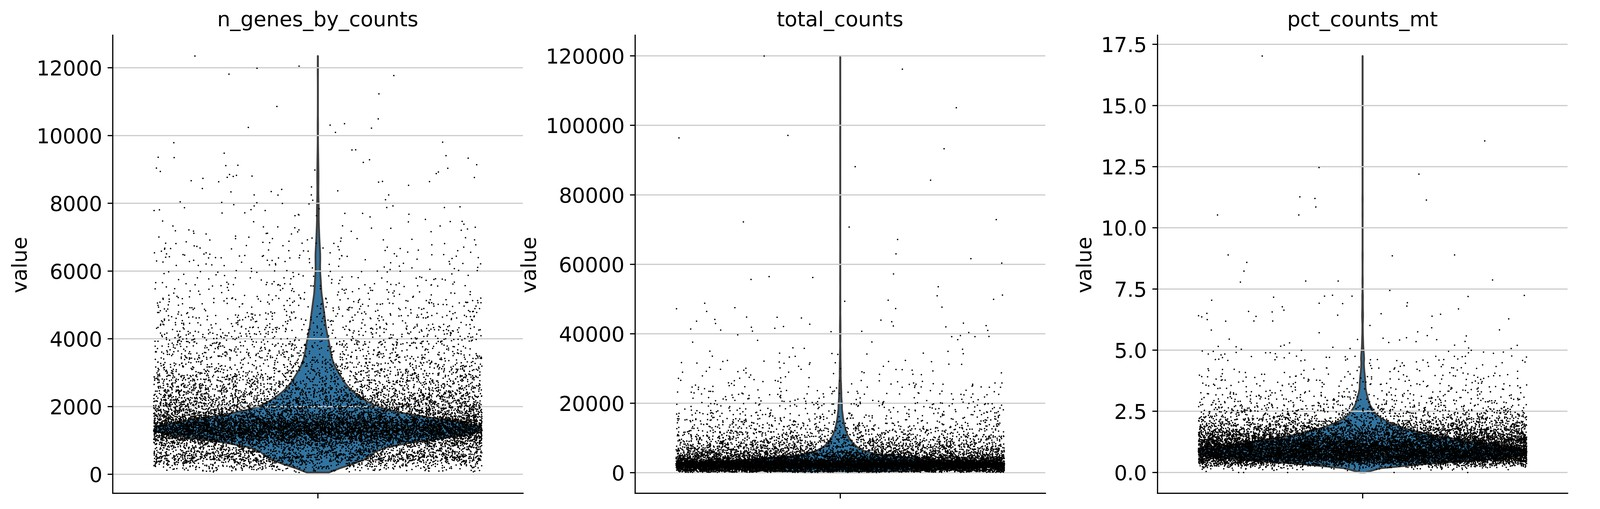

In [4]:
sc.pl.violin(
    adata,
    ["n_genes_by_counts", "total_counts", "pct_counts_mt"],
    jitter=0.4,
    multi_panel=True,
)

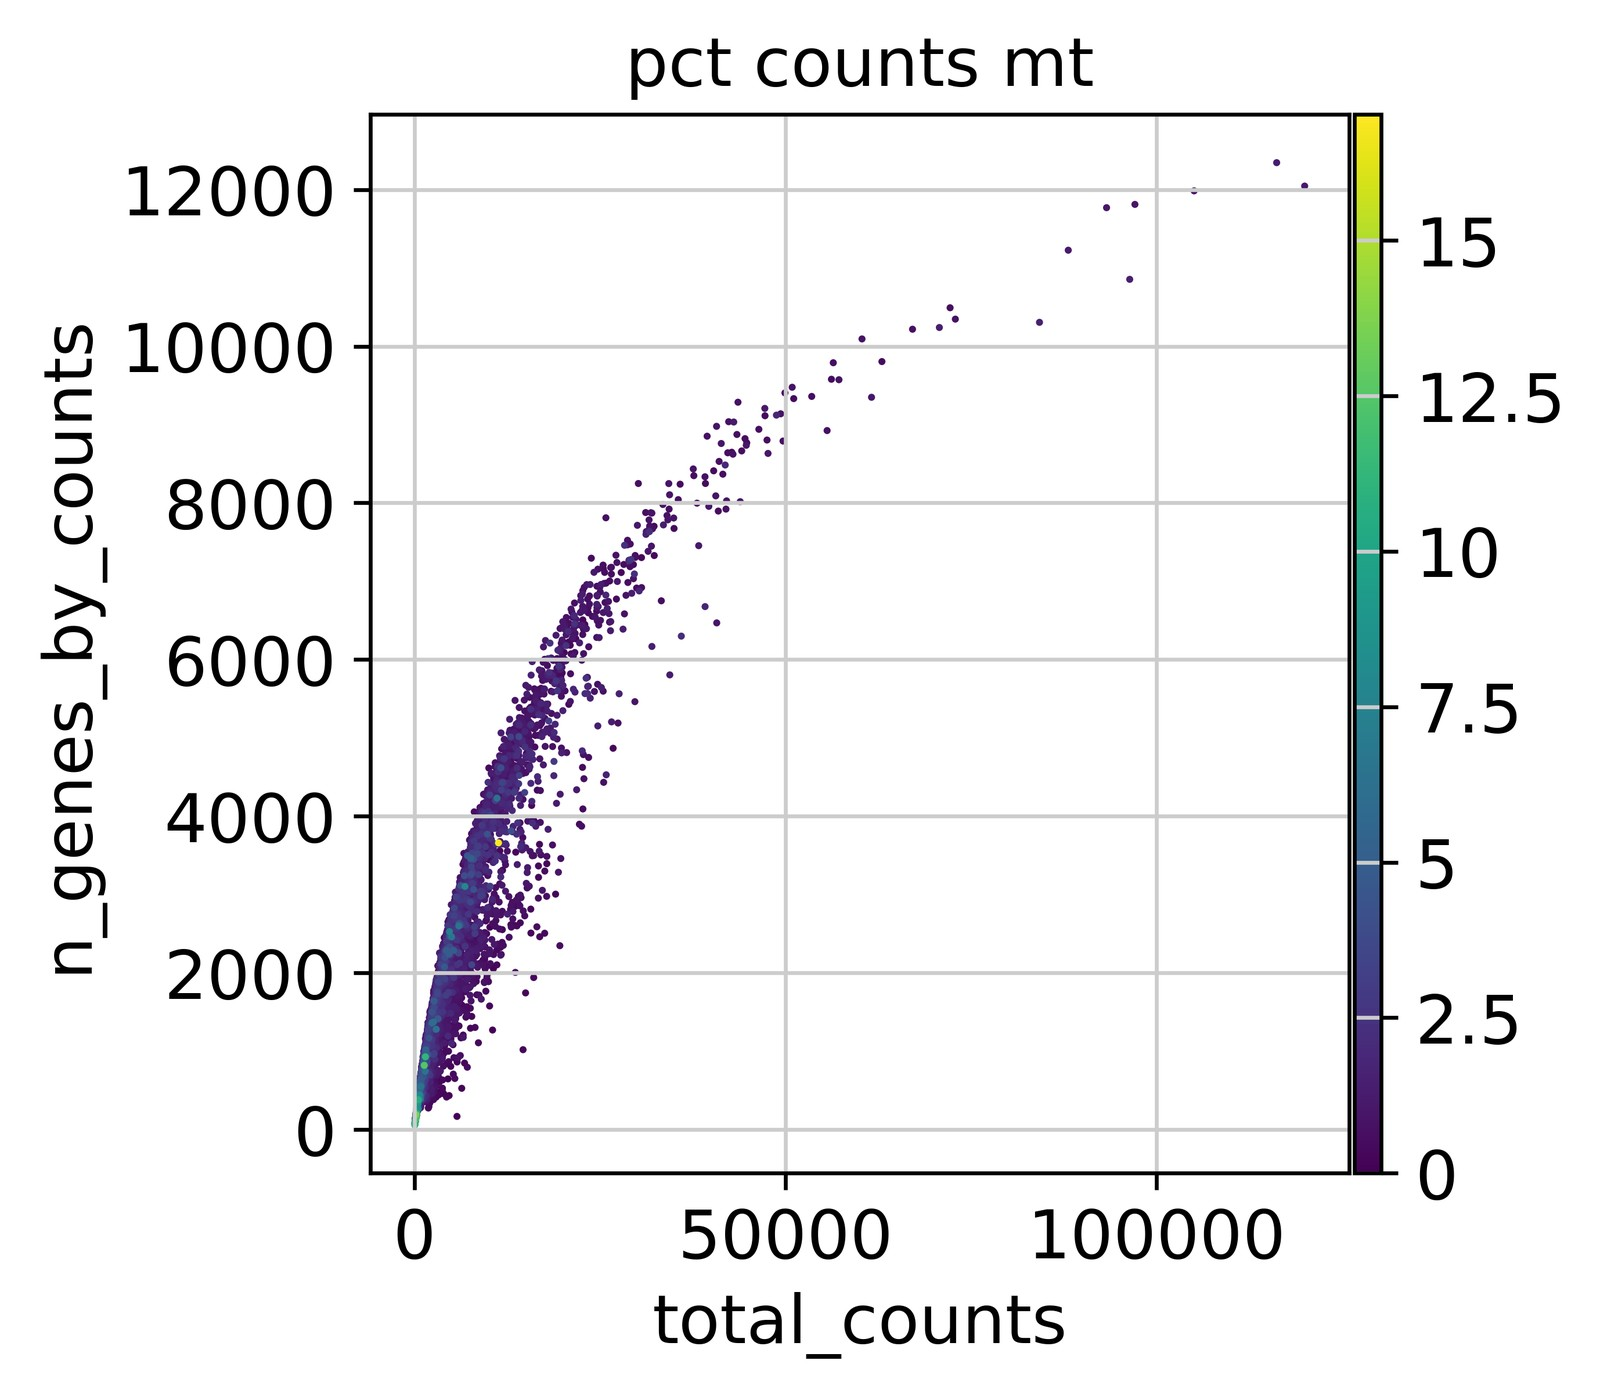

In [5]:
sc.pl.scatter(adata, "total_counts", "n_genes_by_counts", color="pct_counts_mt")

### ATAC

SnapATAC2 reads each cell's fragments from the fragment file, counts them (`n_fragment`) and
computes TSS enrichment (`tsse`). It has no per-cell nucleosome signal, so we compute it as
Signac does: fragments of 147-294 bp (one nucleosome) divided by fragments under 147 bp
(nucleosome-free).

Reading the fragment file takes several minutes, so these metrics are computed once by
`jobs/04_atac_metrics.sbatch` and saved to `atac_metrics.tsv`; this cell loads them.

In [6]:
# computed by jobs/04_atac_metrics.sbatch
atac_metrics = pd.read_csv(atac_metrics_file, sep="\t", index_col="barcode")
adata.obs = adata.obs.join(atac_metrics[["n_fragment", "tsse", "nucleosome_signal"]])
adata.obs["log1p_n_fragment"] = np.log1p(adata.obs["n_fragment"])
print(adata.obs["n_fragment"].isna().sum(), "cells without ATAC metrics")

0 cells without ATAC metrics


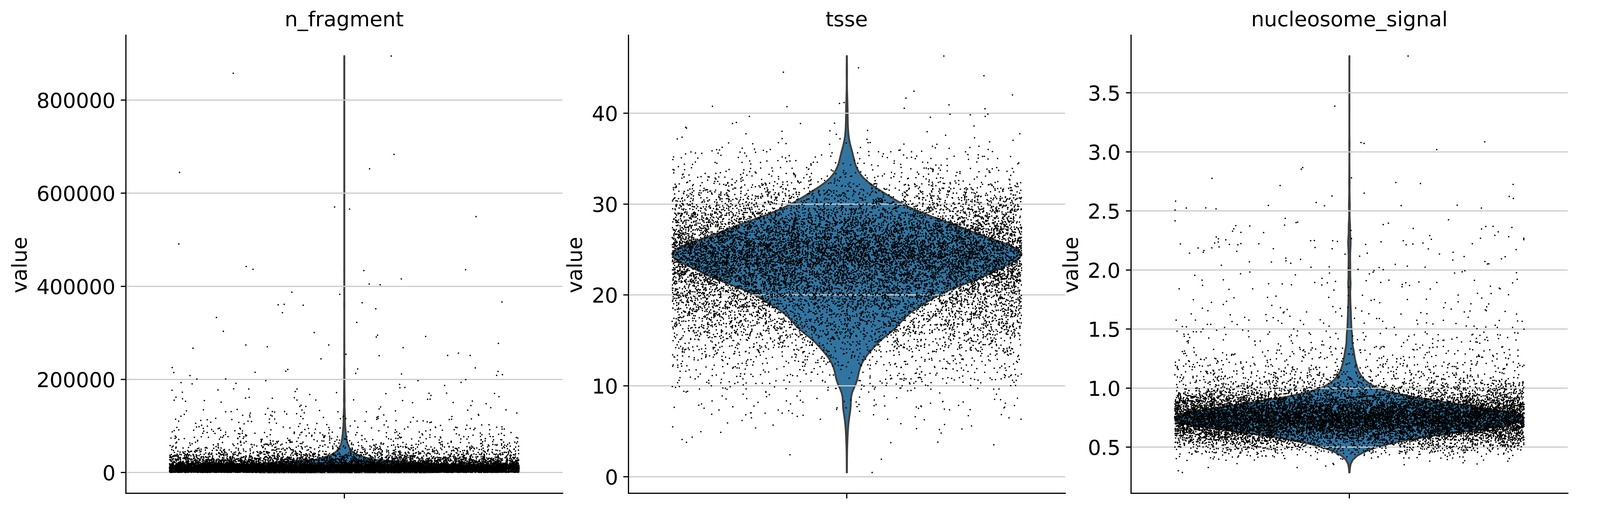

In [7]:
sc.pl.violin(
    adata,
    ["n_fragment", "tsse", "nucleosome_signal"],
    jitter=0.4,
    multi_panel=True,
)

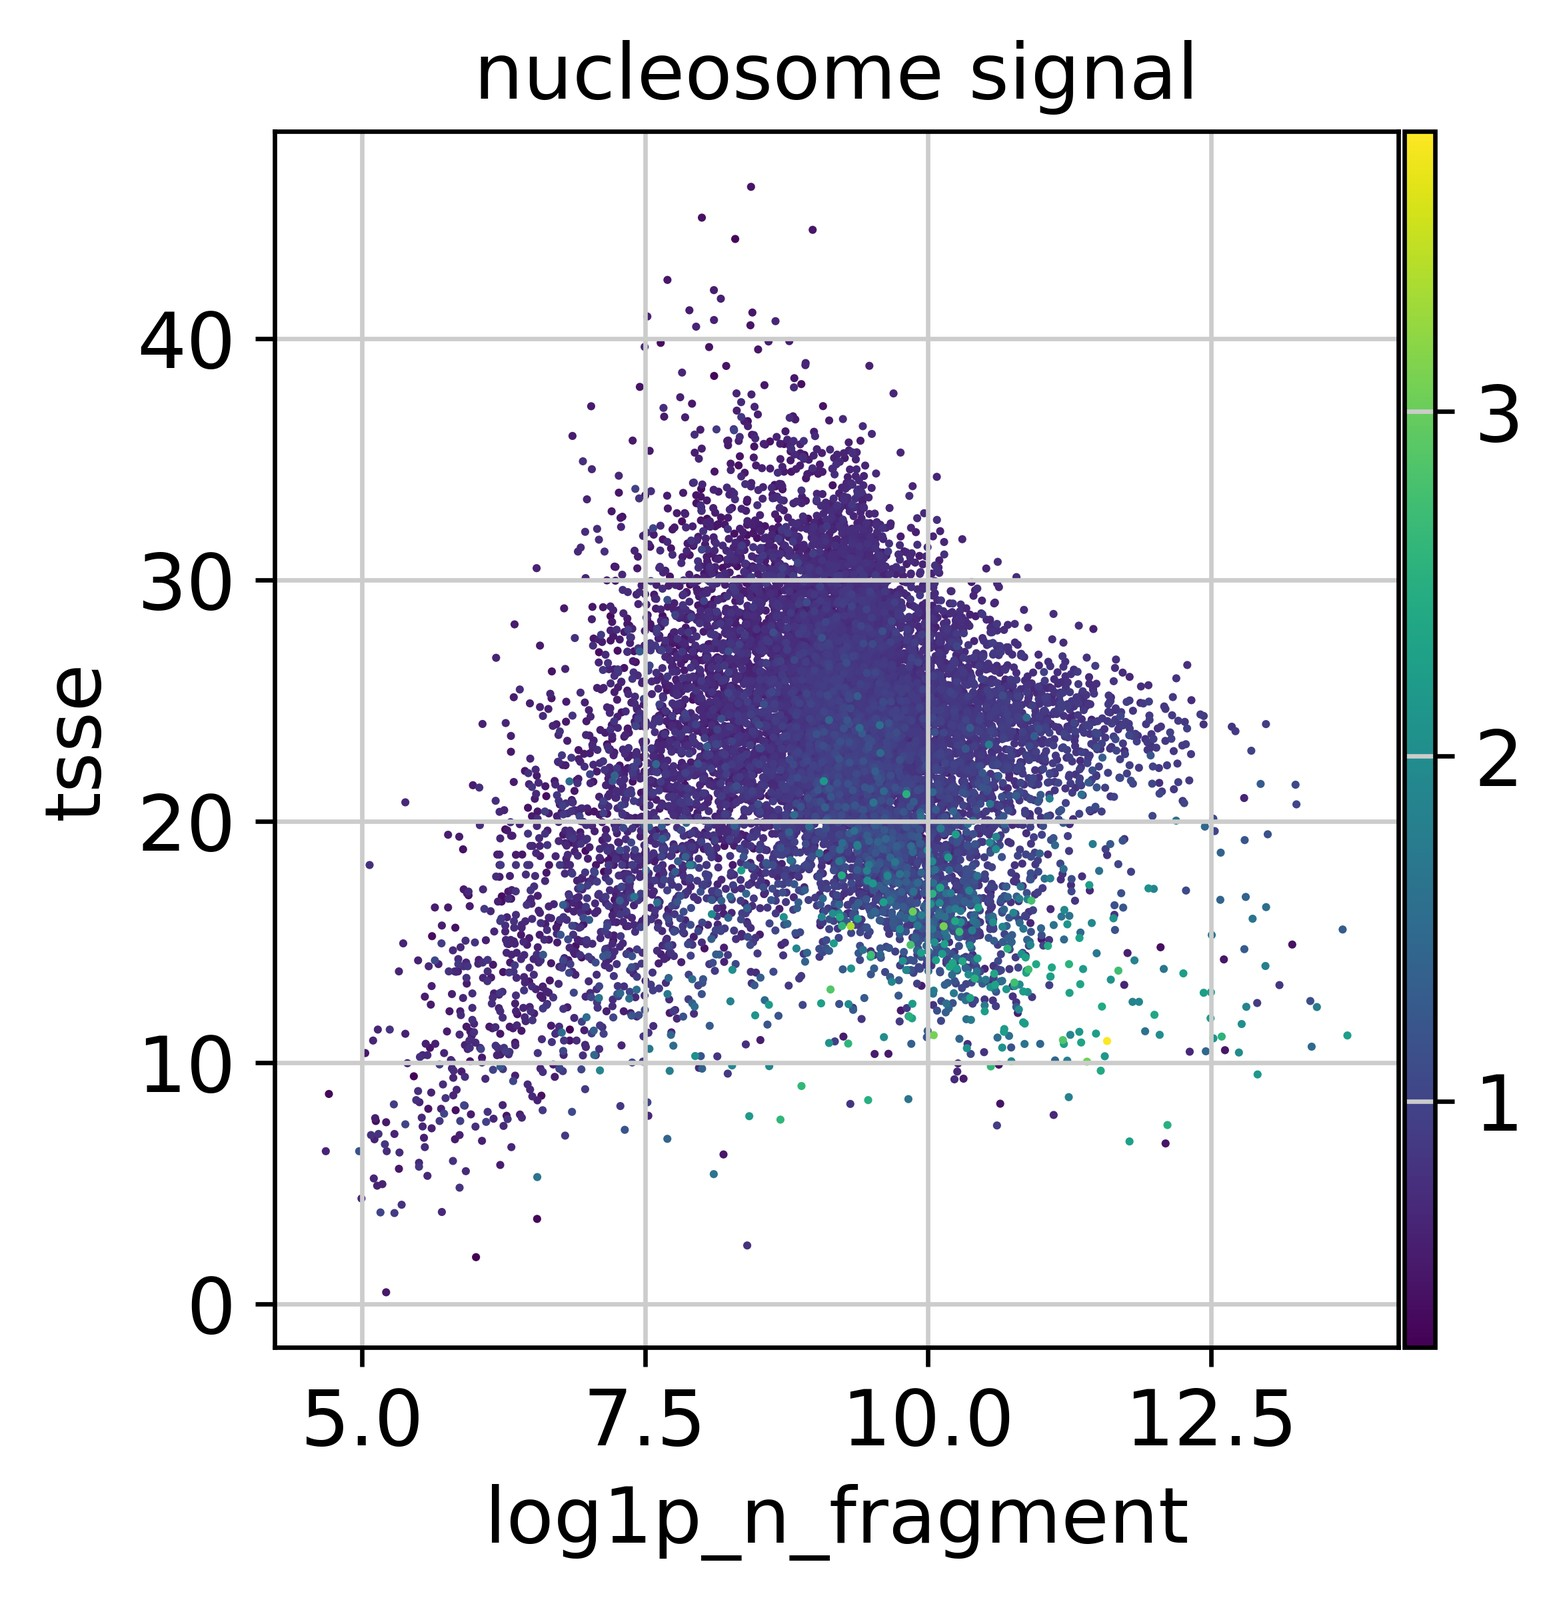

In [8]:
sc.pl.scatter(adata, "log1p_n_fragment", "tsse", color="nucleosome_signal")

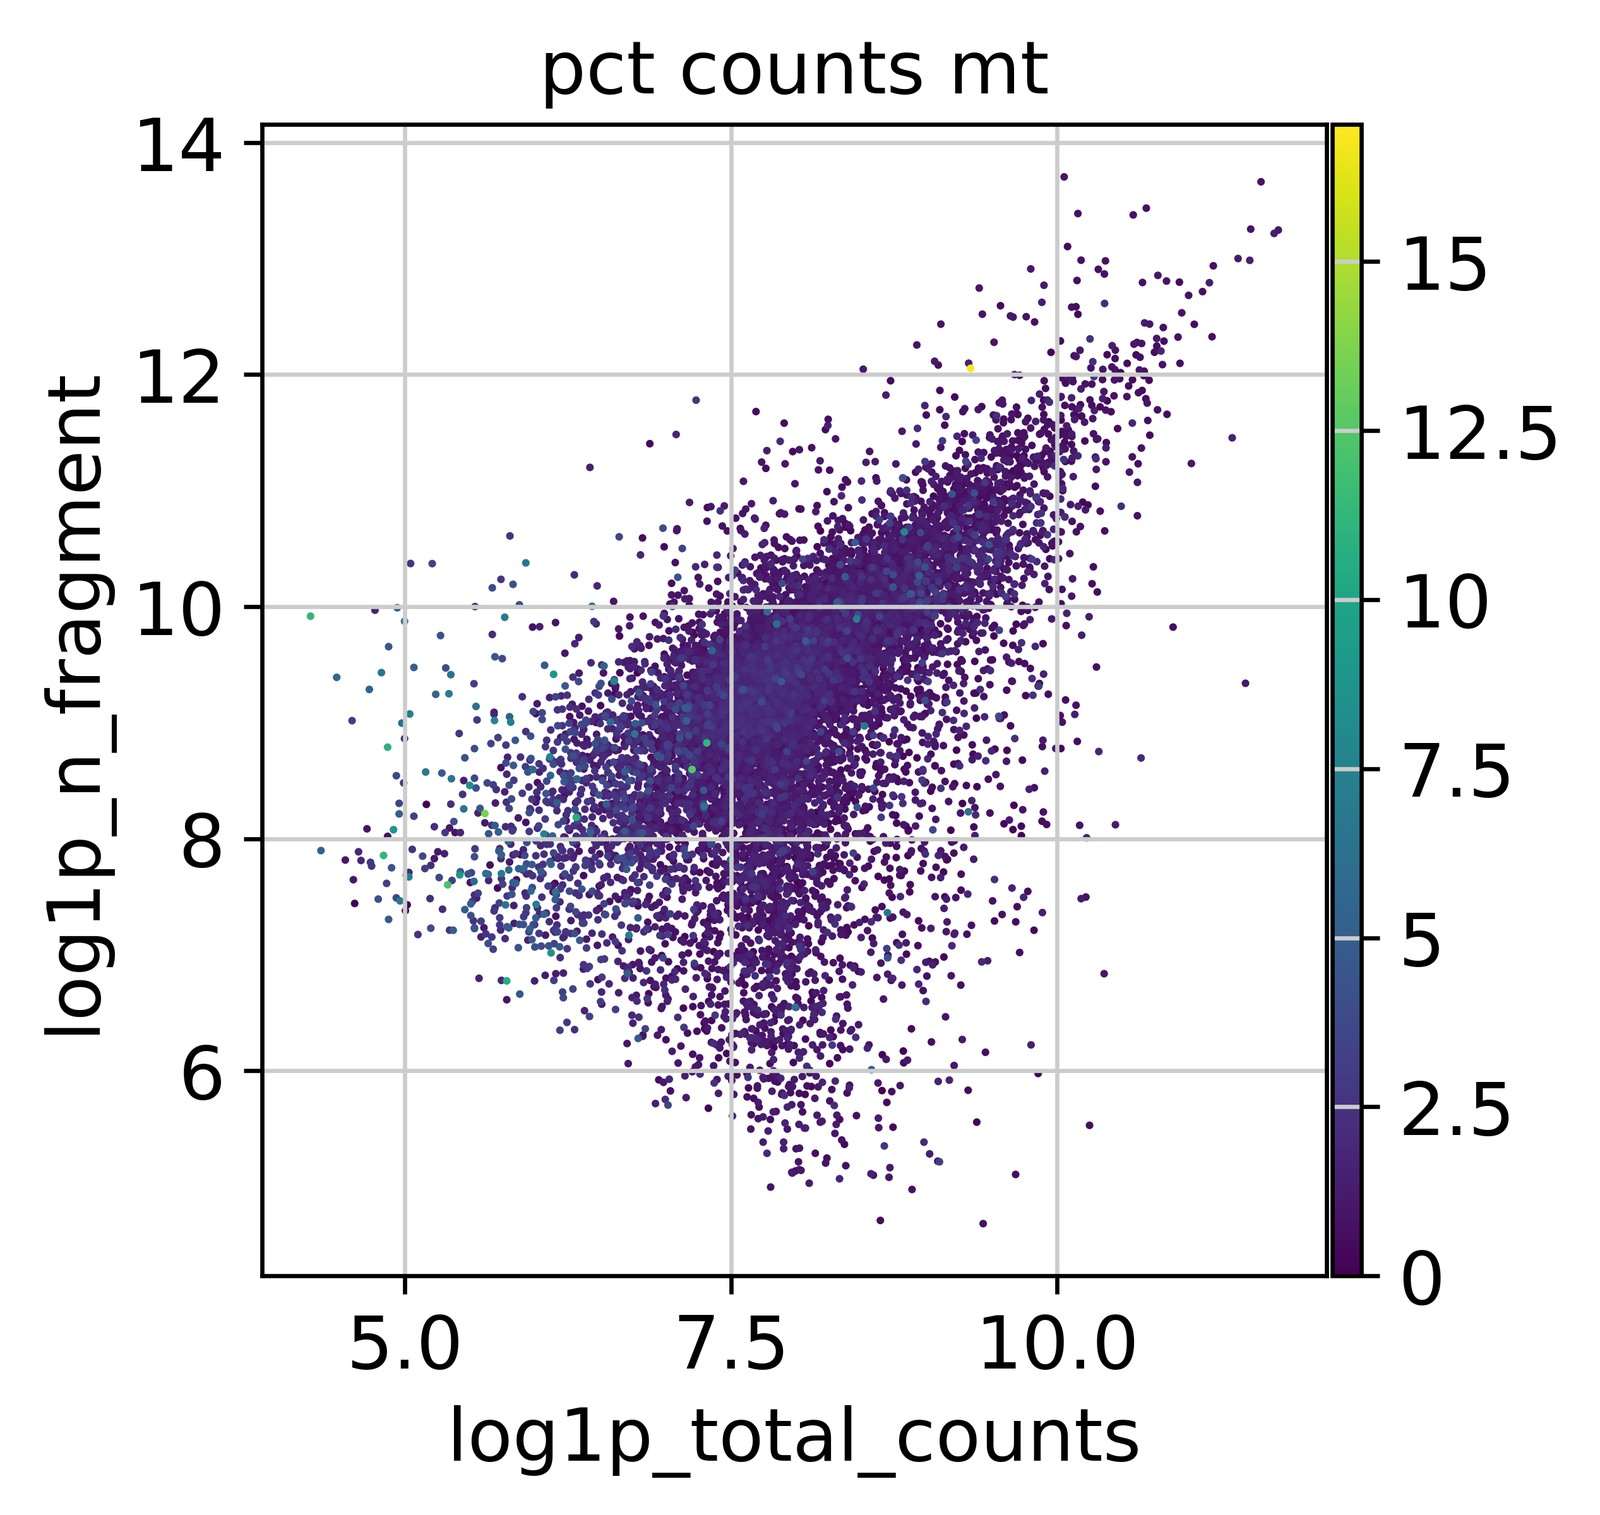

In [9]:
sc.pl.scatter(adata, "log1p_total_counts", "log1p_n_fragment", color="pct_counts_mt")

## Light filter

Removes barcodes that aren't usable cells in either modality: fewer than 100 genes (RNA) or fewer than
1,000 ATAC fragments. Then removes genes detected in fewer than 3 cells, as in the tutorial.

These are fixed floors, not thresholds to tune: doublet detection runs on the cells that remain, so
changing them would change the doublet scores. The thresholds to tune come later, in **First filtering** and **Final filtering**.

In [10]:
light = (adata.obs["n_genes_by_counts"] >= 100) & (adata.obs["n_fragment"] >= 1_000)
print(f"Light filter keeps {light.sum()} of {len(light)} cells ({(~light).mean():.1%} removed)")

adata = adata[light].copy()
sc.pp.filter_genes(adata, min_cells=3)

# Saving count data
adata.layers["counts"] = adata.X.copy()
adata

Light filter keeps 13533 of 14068 cells (3.8% removed)


AnnData object with n_obs × n_vars = 13533 × 27546
    obs: 'sample', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'n_fragment', 'tsse', 'nucleosome_signal', 'log1p_n_fragment'
    var: 'gene_ids', 'feature_types', 'genome', 'interval', 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells'
    layers: 'counts'

## Doublet detection

Two independent calls, one per modality:

- **Scrublet** (RNA) compares each cell with simulated doublets.
- **AMULET** (ATAC) flags cells with more loci covered by more than two reads than a single
  diploid nucleus should have. It was run by `jobs/03_amulet.sbatch`; here we read its q-values.

Cells are only **flagged** here. They are removed in **First filtering**, together with the QC checks, so the
preview there shows QC failures and doublets side by side.

AMULET was run on all Cell Ranger-called cells, before QC, which is how its documentation intends it
to be used (its input is Cell Ranger's list of called cells). Re-running it on QC-passing cells only
was tested: it flagged every cell the current run flags plus another 150-220 per dataset, pushing
doublet rates well above 10x's expected rates, so the current approach was kept.

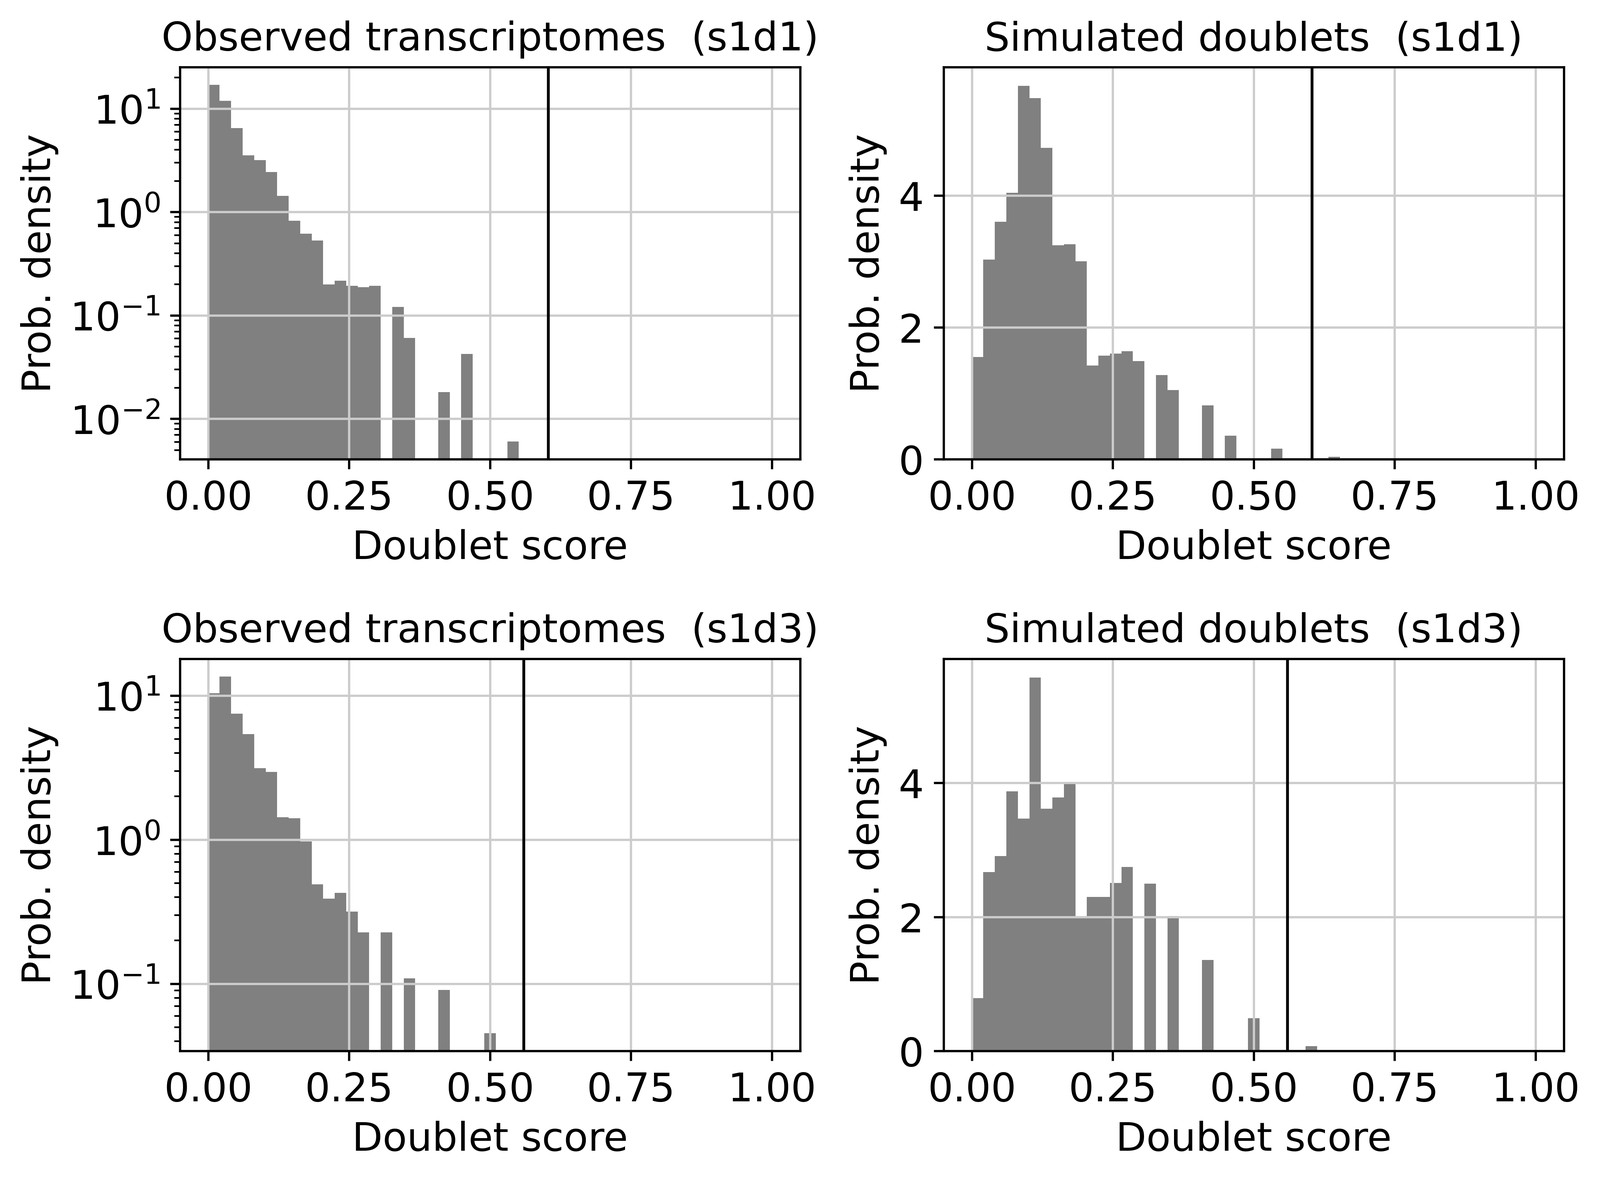

In [11]:
sc.pp.scrublet(adata, batch_key="sample")  # simulated doublets only within a sample
# the vertical lines are Scrublet's automatic thresholds, which are not used (see below)
sc.pl.scrublet_score_distribution(adata)

Scrublet's automatic threshold doesn't suit this dataset, so the threshold is set from 10x Genomics'
expected doublet rate instead.

**Rule:** separately per sample, flag the top X% of Scrublet scores. X is 10x's expected doublet rate of about
0.8% per 1,000 cells recovered, i.e. that sample's Cell Ranger-called cells:
- s1d1: 8,442 cells, so 6.8%;
- s1d3: 5,626 cells, so 4.5%.

It prints each sample's score quantiles, threshold and flagged rate.

In [12]:
# Cell Ranger-called cells per sample (before the light filter)
called = sc.read_10x_h5(h5_file).obs_names.str.rsplit("-", n=1).str[1].map(SAMPLES).value_counts()

adata.obs["predicted_doublet"] = False
for sample, n_called in called.items():
    in_sample = adata.obs["sample"] == sample
    scores = adata.obs.loc[in_sample, "doublet_score"]
    # 10x guideline: ~0.8% doublets per 1,000 cells recovered
    expected_rate = 0.008 * n_called / 1000
    # flag the top expected_rate of scores; >= so cells tied at the threshold are flagged too
    threshold = scores.quantile(1 - expected_rate)
    adata.obs.loc[in_sample, "predicted_doublet"] = scores >= threshold
    print(f"{sample}: score quantiles {scores.quantile([0.90, 0.95, 0.98, 0.99]).round(3).tolist()}; "
          f"expected rate {expected_rate:.1%} -> threshold {threshold:.3f}, "
          f"flags {(scores >= threshold).sum()} cells ({(scores >= threshold).mean():.1%})")

/gpfs/scratch/qp252877/anaconda/envs/azimuth/lib/python3.10/site-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/gpfs/scratch/qp252877/anaconda/envs/azimuth/lib/python3.10/site-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


s1d1: score quantiles [0.121, 0.157, 0.232, 0.272]; expected rate 6.8% -> threshold 0.140, flags 610 cells (7.5%)
s1d3: score quantiles [0.138, 0.181, 0.257, 0.285]; expected rate 4.5% -> threshold 0.196, flags 256 cells (4.7%)


In [13]:
amulet = pd.concat([pd.read_csv(f, sep="\t", index_col="barcode") for f in amulet_files])
adata.obs["amulet_q"] = amulet["q-value"].reindex(adata.obs_names)
adata.obs["amulet_multiplet"] = adata.obs["amulet_q"] < 0.01
print(adata.obs.groupby("sample", observed=True)["amulet_multiplet"].agg(["sum", "mean"]).round(3).to_string())

pd.crosstab(adata.obs["predicted_doublet"], adata.obs["amulet_multiplet"])

        sum   mean
sample            
s1d1    351  0.043
s1d3    299  0.055


amulet_multiplet,False,True
predicted_doublet,,
False,12135,532
True,748,118


In [14]:
# one label per cell for plotting
adata.obs["doublet"] = pd.Categorical(
    np.select(
        [adata.obs["predicted_doublet"] & adata.obs["amulet_multiplet"],
         adata.obs["predicted_doublet"],
         adata.obs["amulet_multiplet"]],
        ["both", "Scrublet", "AMULET"],
        default="none",
    ),
    categories=["none", "Scrublet", "AMULET", "both"],
)
adata.obs["doublet"].value_counts()

doublet
none        12135
Scrublet      748
AMULET        532
both          118
Name: count, dtype: int64

## Exploratory clustering

Normalise, select highly variable genes, PCA, neighbours, UMAP and Leiden on the light-filtered cells,
as in the tutorial. These clusters are only used to judge QC; everything is redone on the final cells
after filtering. The steps are written once as a function, used here and again in **Final clustering**.

In [15]:
def normalise_and_cluster(adata, batch_key=None):
    """Normalise, log1p, HVGs, PCA, kNN graph, UMAP and Leiden, starting from the raw counts."""
    adata.X = adata.layers["counts"].copy()
    adata.uns.pop("log1p", None)
    sc.pp.normalize_total(adata)
    sc.pp.log1p(adata)
    sc.pp.highly_variable_genes(adata, n_top_genes=2000, batch_key=batch_key)
    sc.tl.pca(adata)
    sc.pp.neighbors(adata)
    sc.tl.umap(adata)
    sc.tl.leiden(adata, flavor="igraph", n_iterations=2)


normalise_and_cluster(adata)

/gpfs/scratch/qp252877/anaconda/envs/azimuth/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


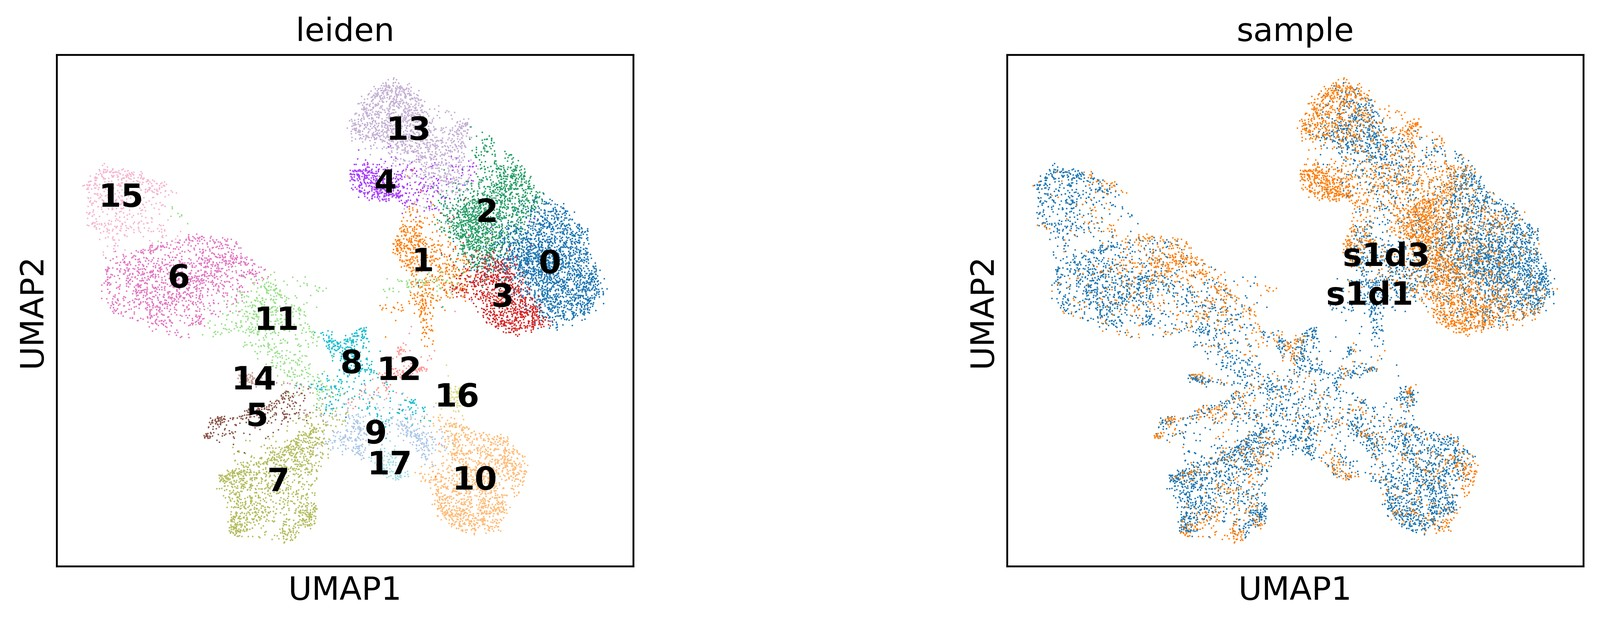

In [16]:
sc.pl.umap(adata, color=["leiden", "sample"], legend_loc="on data", wspace=0.5, size=2)

## Re-assess QC on the exploratory clusters

Look at where low-quality cells and doublets sit on the exploratory clusters:

- **Cells failing a check form their own cluster** with no clear marker genes: a technical artefact,
  so remove them.
- **They are scattered through normal clusters:** the threshold may be too strict, removing healthy cells.
- **They are concentrated in one biological cell type:** the threshold is biased against that type (some
  cell types naturally have lower TSSE or more mito or RNA), so consider relaxing it.

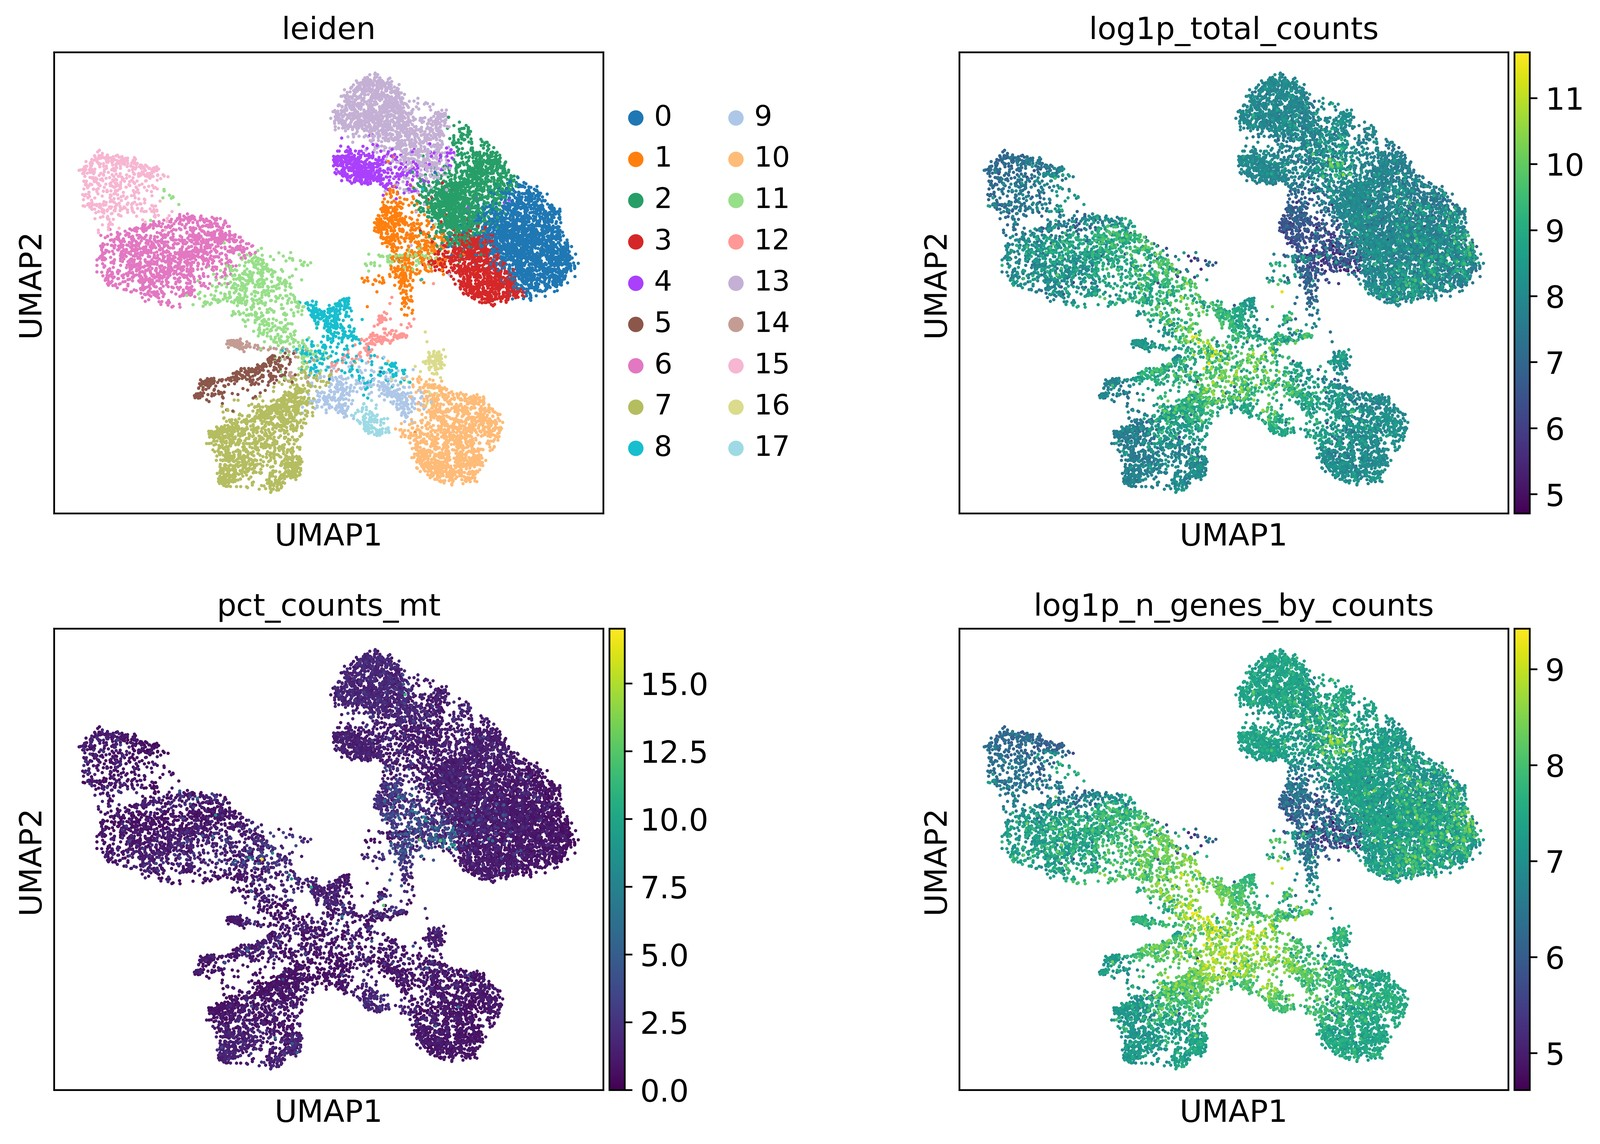

In [17]:
sc.pl.umap(
    adata,
    color=["leiden", "log1p_total_counts", "pct_counts_mt", "log1p_n_genes_by_counts"],
    wspace=0.5,
    ncols=2,
)

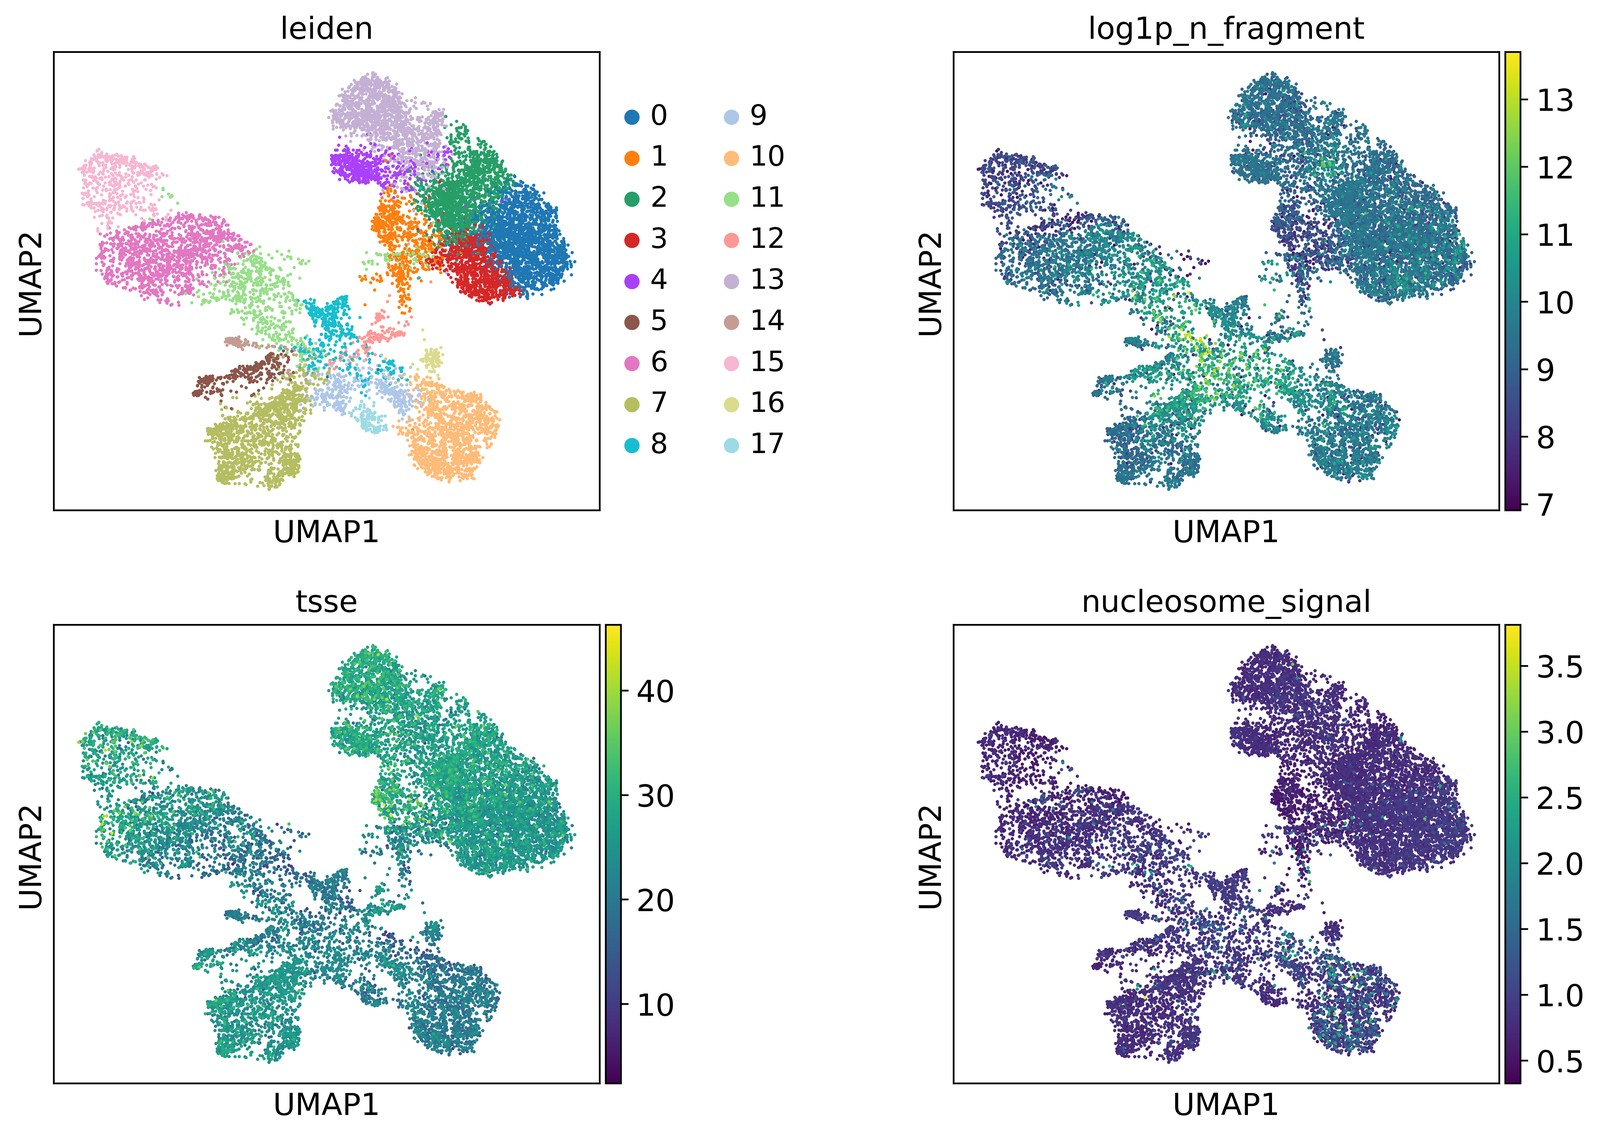

In [18]:
sc.pl.umap(
    adata,
    color=["leiden", "log1p_n_fragment", "tsse", "nucleosome_signal"],
    wspace=0.5,
    ncols=2,
)

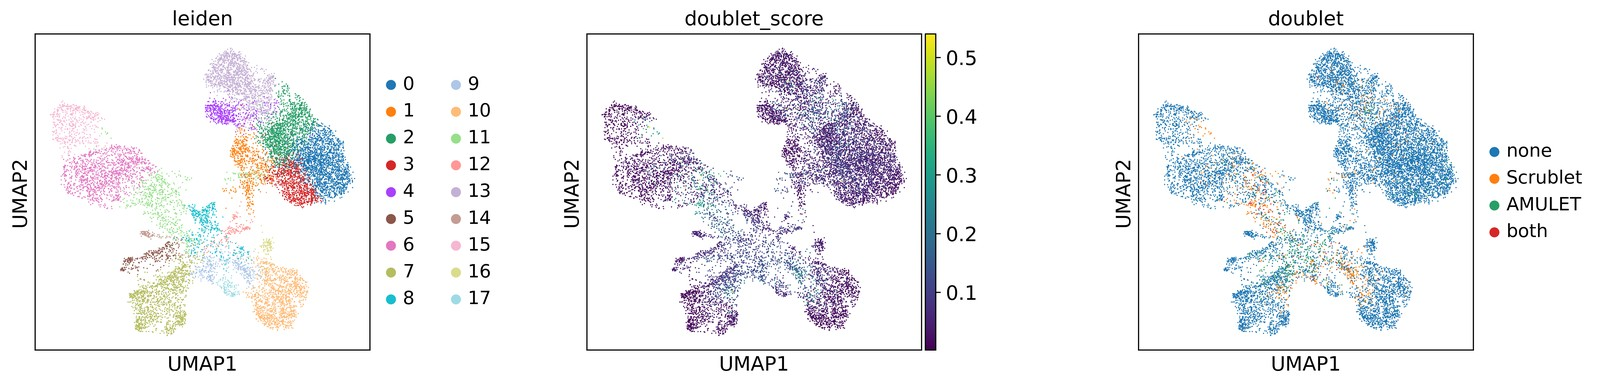

In [19]:
sc.pl.umap(
    adata,
    color=["leiden", "doublet_score", "doublet"],
    wspace=0.5,
    size=3,
)

In [20]:
# # cluster markers, to judge whether a cluster is biology or an artefact
# sc.tl.rank_genes_groups(adata, groupby="leiden", method="wilcoxon")
# sc.pl.rank_genes_groups_dotplot(adata, groupby="leiden", standard_scale="var", n_genes=4)

### First filtering: low-quality cells and doublets

Removes low-quality cells and the cells flagged by Scrublet or AMULET. There are no upper limits on RNA
counts or ATAC fragments yet: very high values are often doublets, which the two detectors are meant to
catch, so this step leaves them to Scrublet and AMULET. The gene minimum stays at the light filter's 100,
and the ATAC fragment minimum (1,000) is already enforced by the light filter.

The first cell only previews: it reports how many cells each check would remove and, per exploratory
cluster, the share failing each check. Re-run it as you adjust the numbers, then apply.

In [21]:
checks = pd.DataFrame({
    "RNA: genes >= 100": adata.obs["n_genes_by_counts"] >= 100,
    "RNA: counts >= 500": adata.obs["total_counts"] >= 500,
    "RNA: mito <= 10%": adata.obs["pct_counts_mt"] <= 10,
    "ATAC: TSSE >= 5": adata.obs["tsse"] >= 5,
    "ATAC: nucleosome signal < 2": adata.obs["nucleosome_signal"] < 2,
    "Doublet: Scrublet": ~adata.obs["predicted_doublet"],
    "Doublet: AMULET": ~adata.obs["amulet_multiplet"],
})

summary = pd.DataFrame({
    "fail": (~checks).sum(),
    "fail only this check": {c: (~checks[c] & checks.drop(columns=c).all(axis=1)).sum() for c in checks},
})
print(summary.to_string())

keep = checks.all(axis=1)
print(f"\nWould remove {(~keep).sum()} of {len(keep)} cells ({(~keep).mean():.1%}), keeping {keep.sum()}")

adata.obs["qc"] = pd.Categorical(np.where(keep, "keep", "remove"))
print(pd.crosstab(adata.obs["sample"], adata.obs["qc"]).to_string())

                             fail  fail only this check
RNA: genes >= 100               0                     0
RNA: counts >= 500            353                   331
RNA: mito <= 10%                6                     3
ATAC: TSSE >= 5                 1                     0
ATAC: nucleosome signal < 2   119                    93
Doublet: Scrublet             866                   723
Doublet: AMULET               650                   525

Would remove 1832 of 13533 cells (13.5%), keeping 11701
qc      keep  remove
sample              
s1d1    6972    1159
s1d3    4729     673


In [22]:
# share of each exploratory cluster failing each check
by_cluster = (~checks).groupby(adata.obs["leiden"], observed=True).mean().round(2)
by_cluster.insert(0, "cells", adata.obs["leiden"].value_counts())
by_cluster

,cells,RNA: genes >= 100,RNA: counts >= 500,RNA: mito <= 10%,ATAC: TSSE >= 5,ATAC: nucleosome signal < 2,Doublet: Scrublet,Doublet: AMULET
leiden,,,,,,,,
0,2047,0.0,0.02,0.00,0.0,0.00,0.01,0.02
1,646,0.0,0.28,0.00,0.0,0.01,0.02,0.00
2,1446,0.0,0.01,0.00,0.0,0.00,0.03,0.00
3,887,0.0,0.08,0.00,0.0,0.00,0.01,0.02
4,546,0.0,0.00,0.00,0.0,0.00,0.03,0.00
5,268,0.0,0.00,0.00,0.0,0.00,0.01,0.12
6,1256,0.0,0.00,0.00,0.0,0.00,0.05,0.02
7,1318,0.0,0.00,0.00,0.0,0.00,0.05,0.10
8,414,0.0,0.00,0.00,0.0,0.02,0.05,0.10


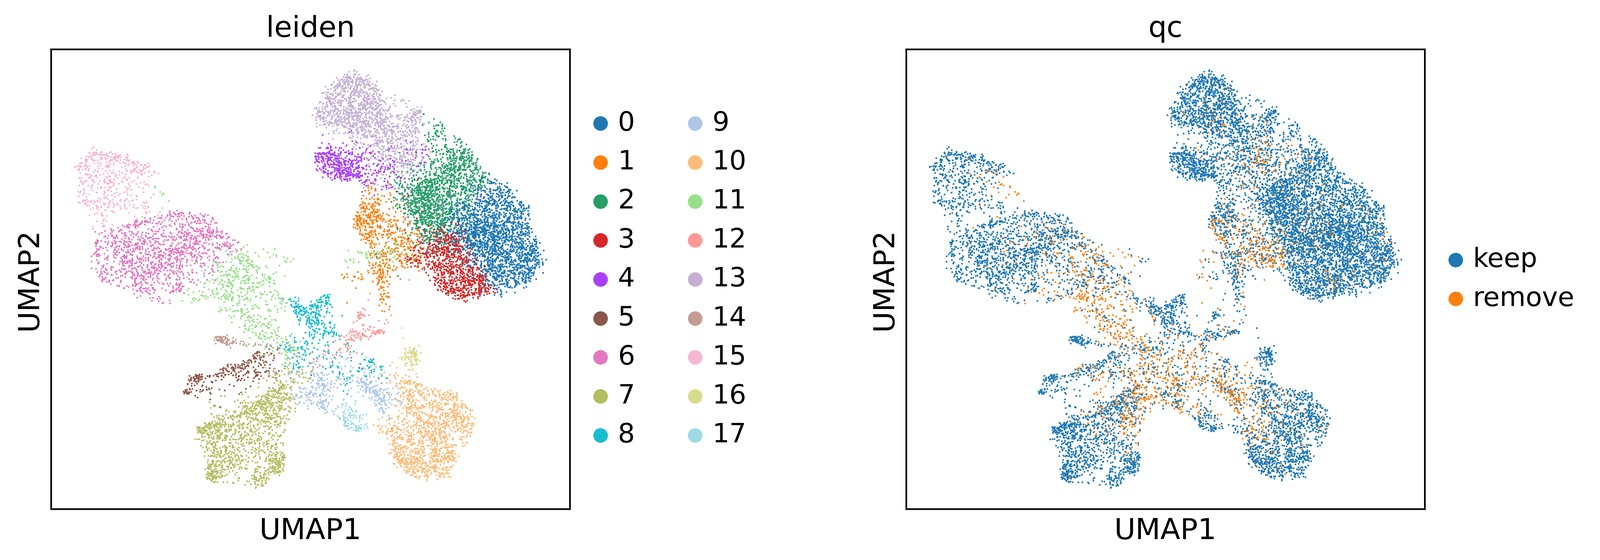

In [23]:
sc.pl.umap(adata, color=["leiden", "qc"], wspace=0.5, size=3)

### Apply the first filter

In [24]:
adata = adata[keep].copy()
adata

AnnData object with n_obs × n_vars = 11701 × 27546
    obs: 'sample', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'n_fragment', 'tsse', 'nucleosome_signal', 'log1p_n_fragment', 'n_genes', 'doublet_score', 'predicted_doublet', 'amulet_q', 'amulet_multiplet', 'doublet', 'leiden', 'qc'
    var: 'gene_ids', 'feature_types', 'genome', 'interval', 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'scrublet', 'log1p', 'hvg', 'pca', 'neighbors', 'umap', 'leiden', 'leiden_colors

## Re-assess QC after the first filtering

The same QC plots and UMAPs as before, now on the cells that remain, re-clustered without the removed
cells. Any doublets the detectors missed should stand out as cells with very high RNA counts or ATAC
fragments, often forming their own small clusters or sitting between cell types. Use these plots to
choose the upper limits in **Final filtering**.

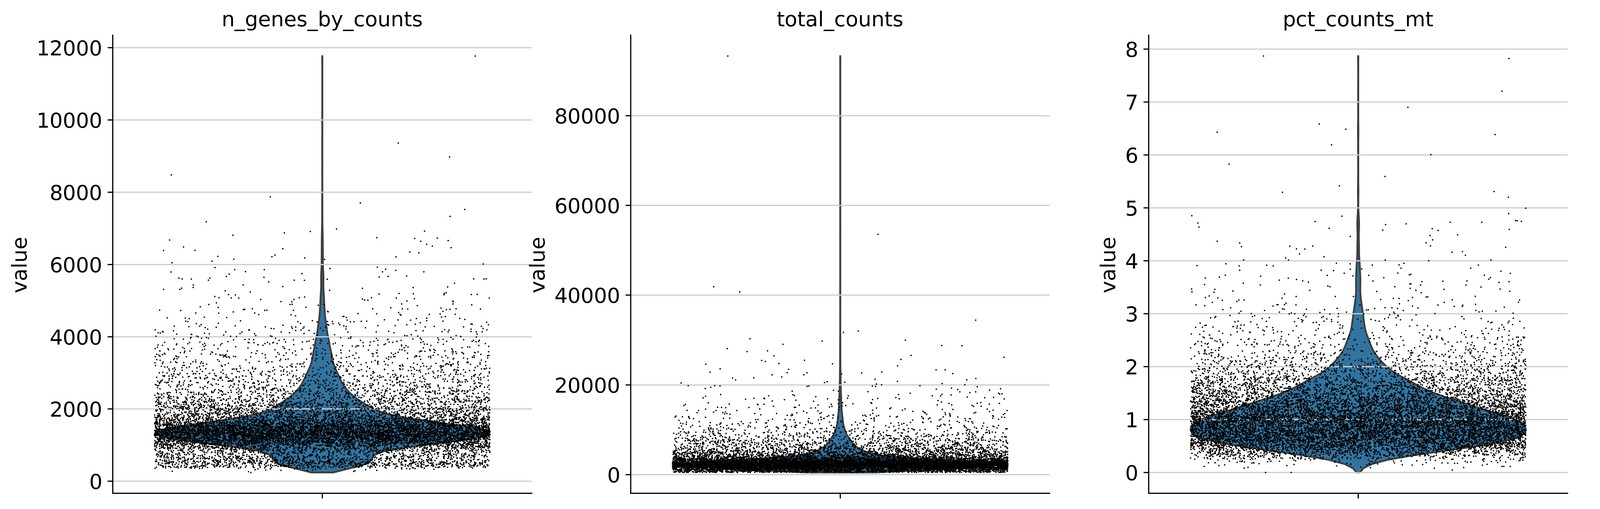

In [25]:
sc.pl.violin(
    adata,
    ["n_genes_by_counts", "total_counts", "pct_counts_mt"],
    jitter=0.4,
    multi_panel=True,
)

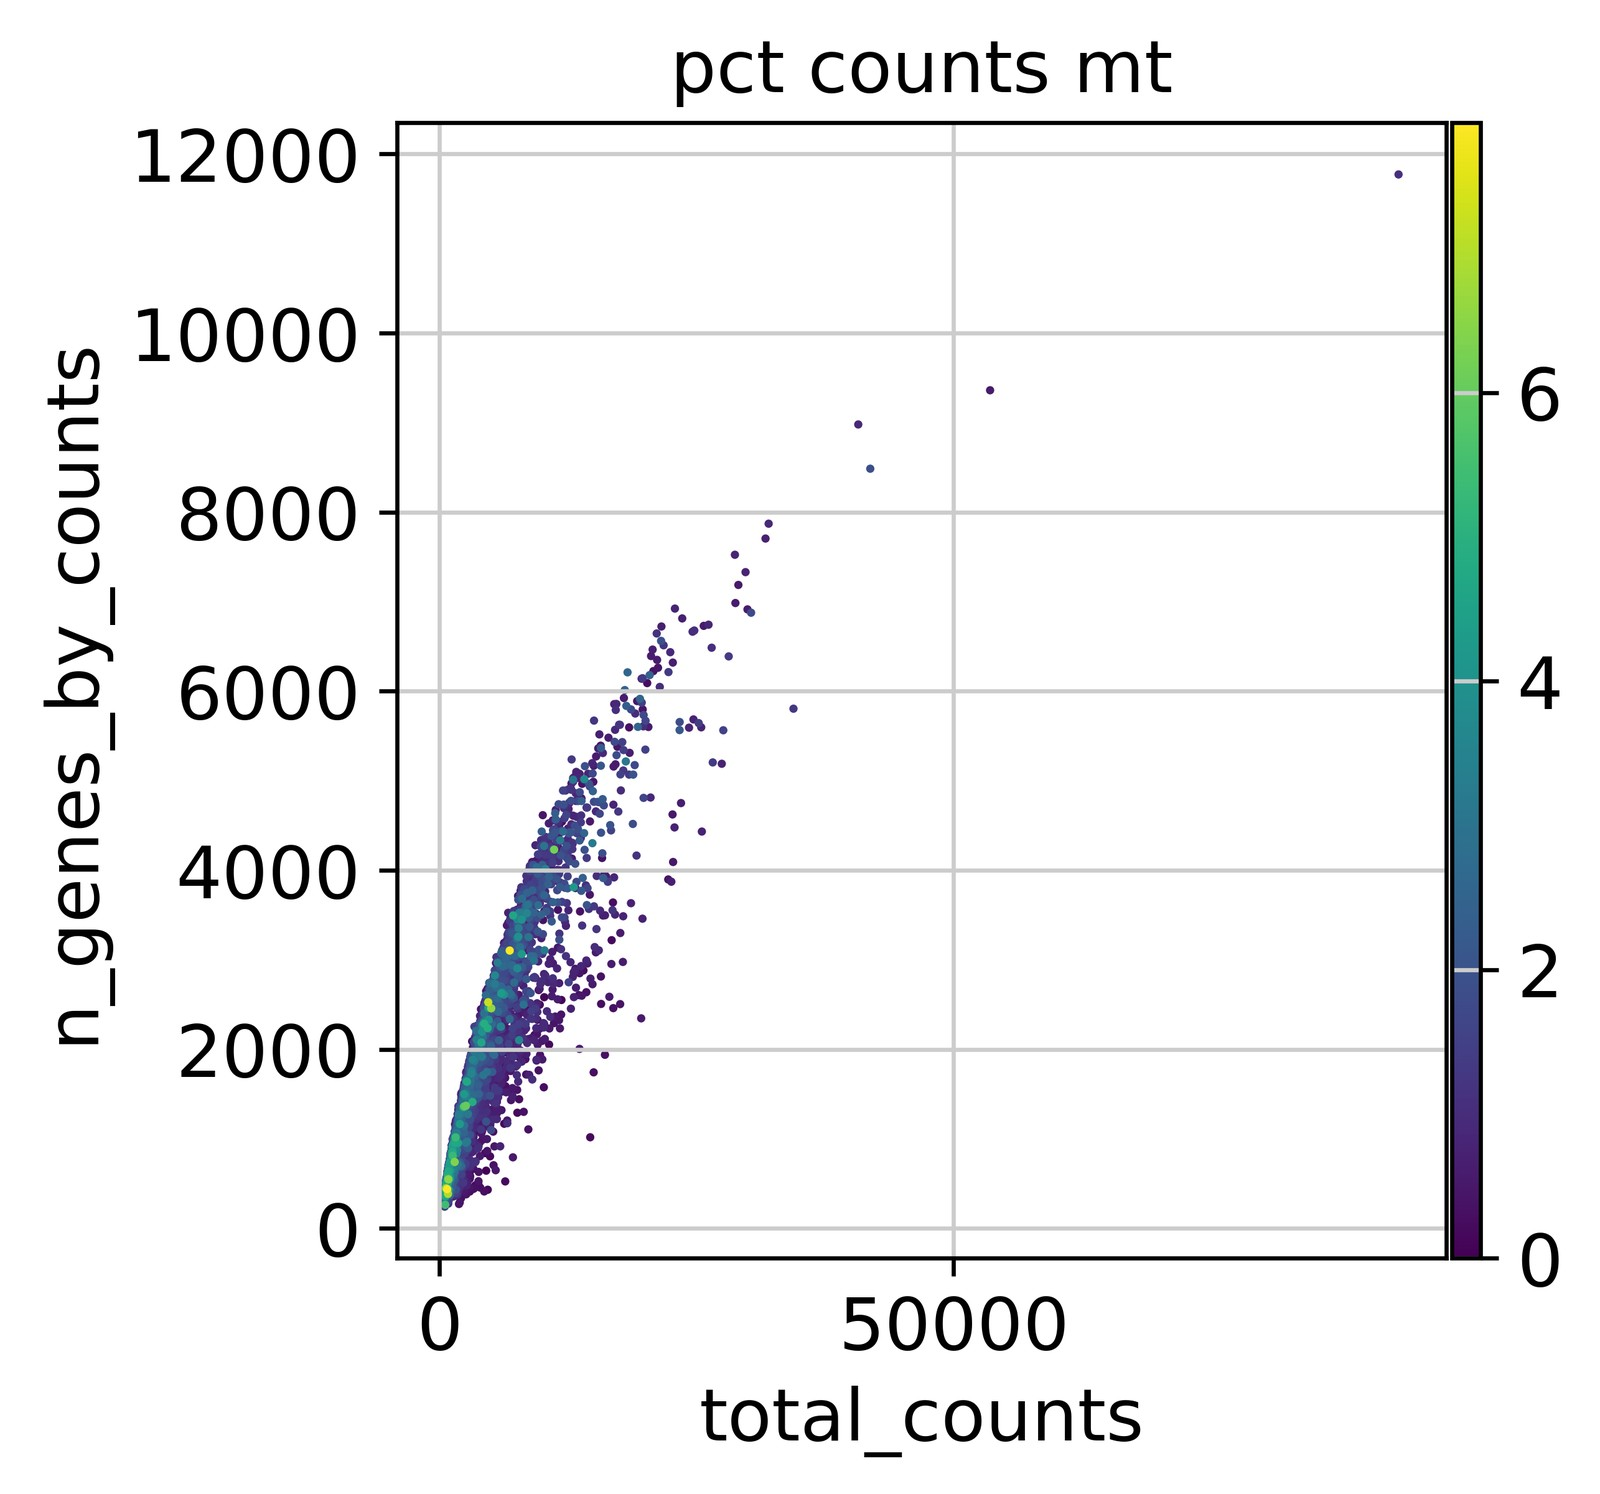

In [26]:
sc.pl.scatter(adata, "total_counts", "n_genes_by_counts", color="pct_counts_mt")

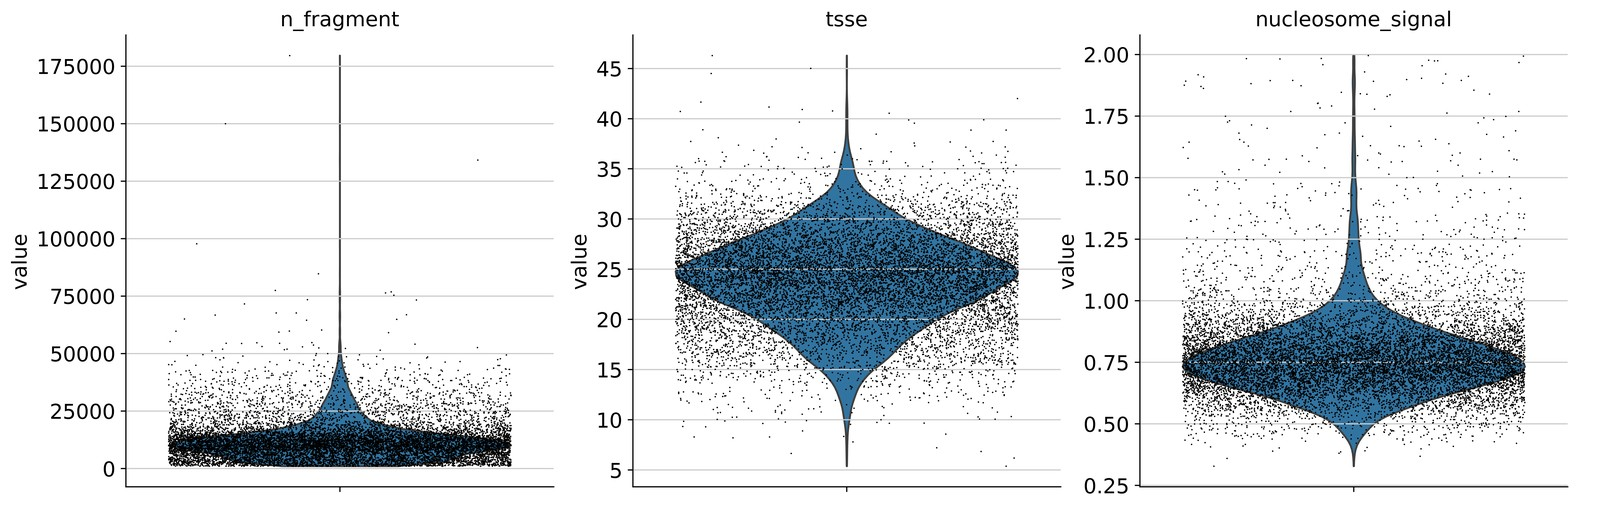

In [27]:
sc.pl.violin(
    adata,
    ["n_fragment", "tsse", "nucleosome_signal"],
    jitter=0.4,
    multi_panel=True,
)

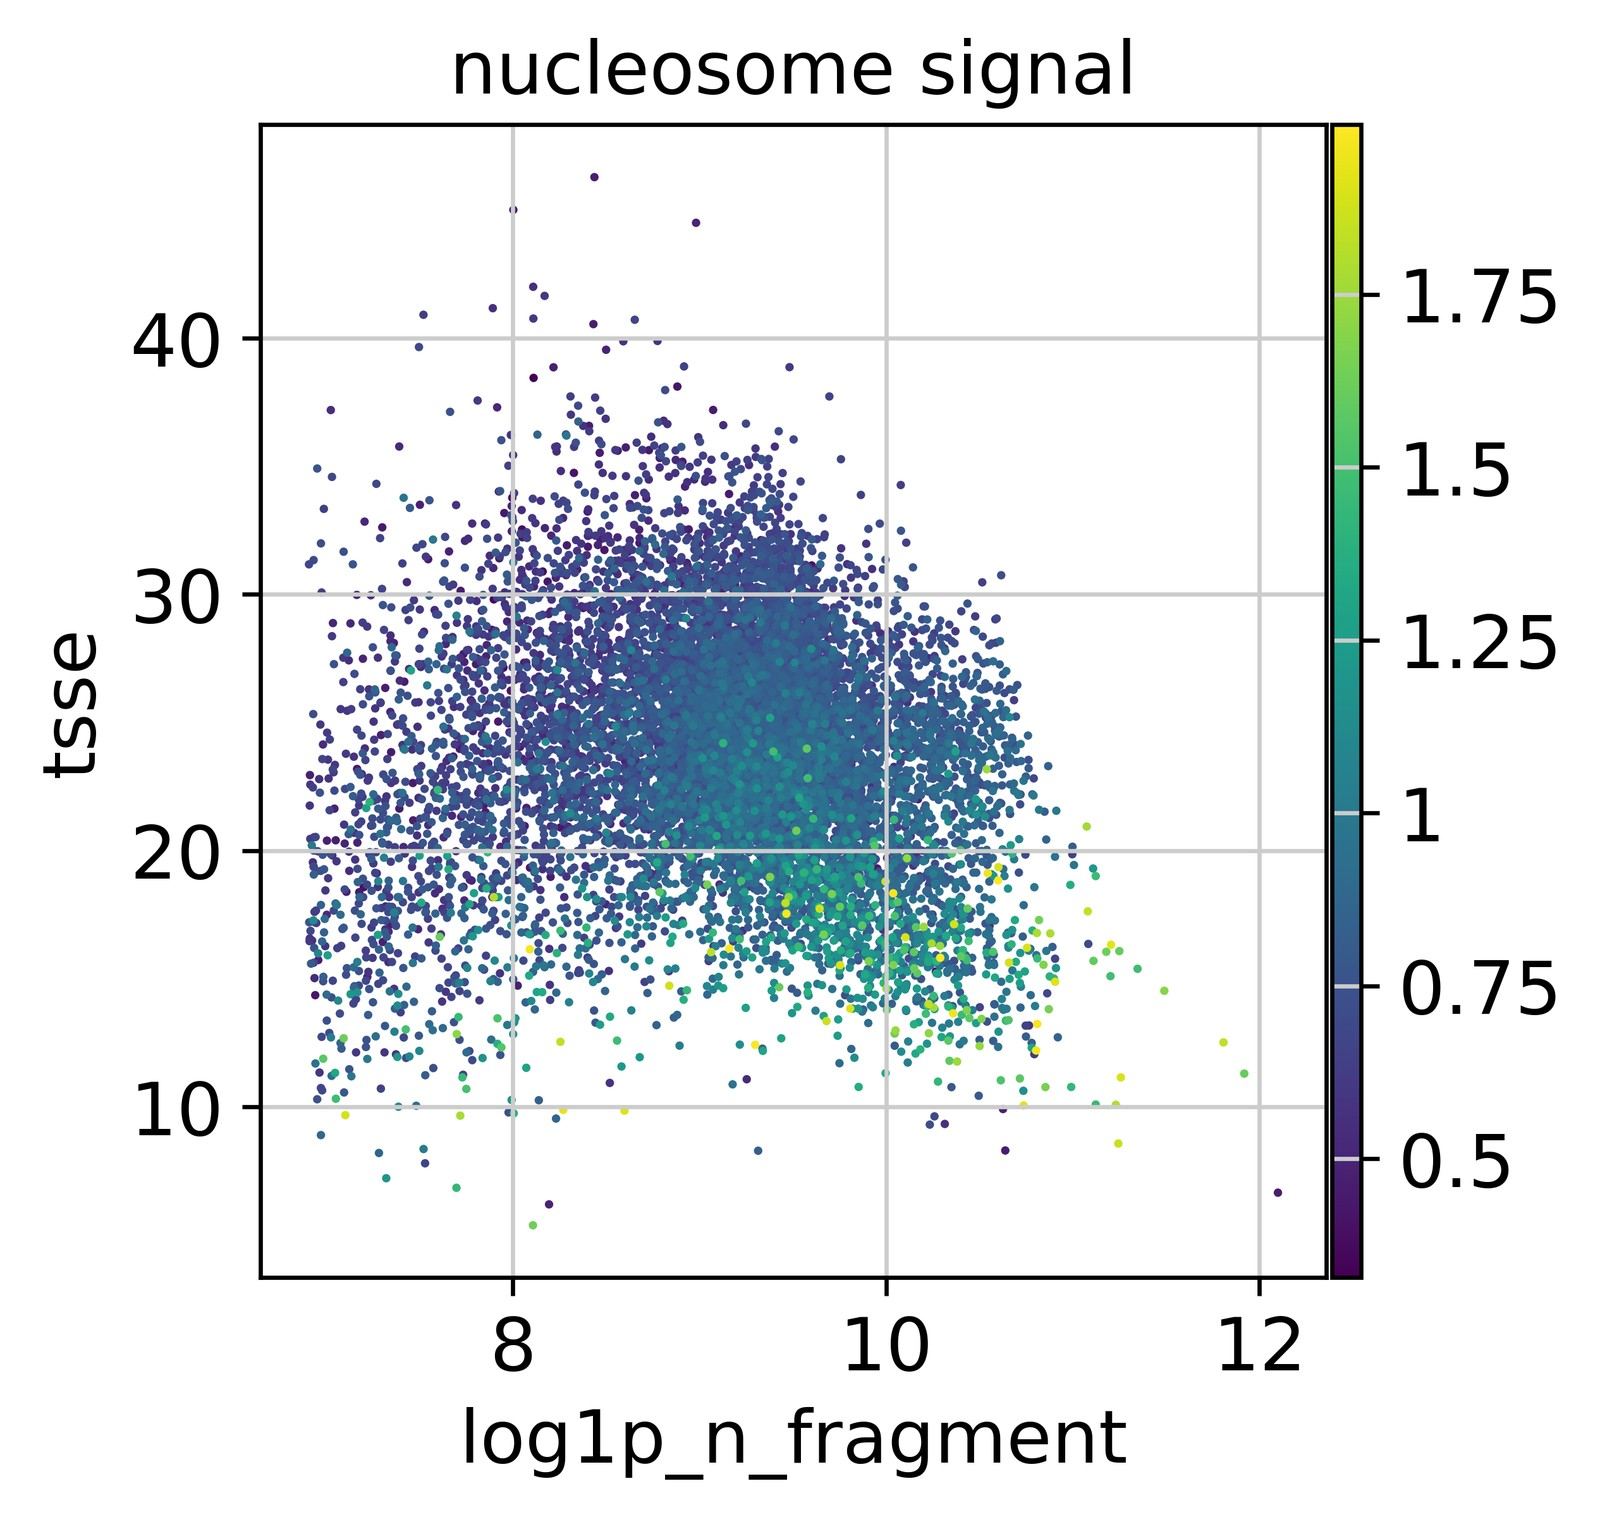

In [28]:
sc.pl.scatter(adata, "log1p_n_fragment", "tsse", color="nucleosome_signal")

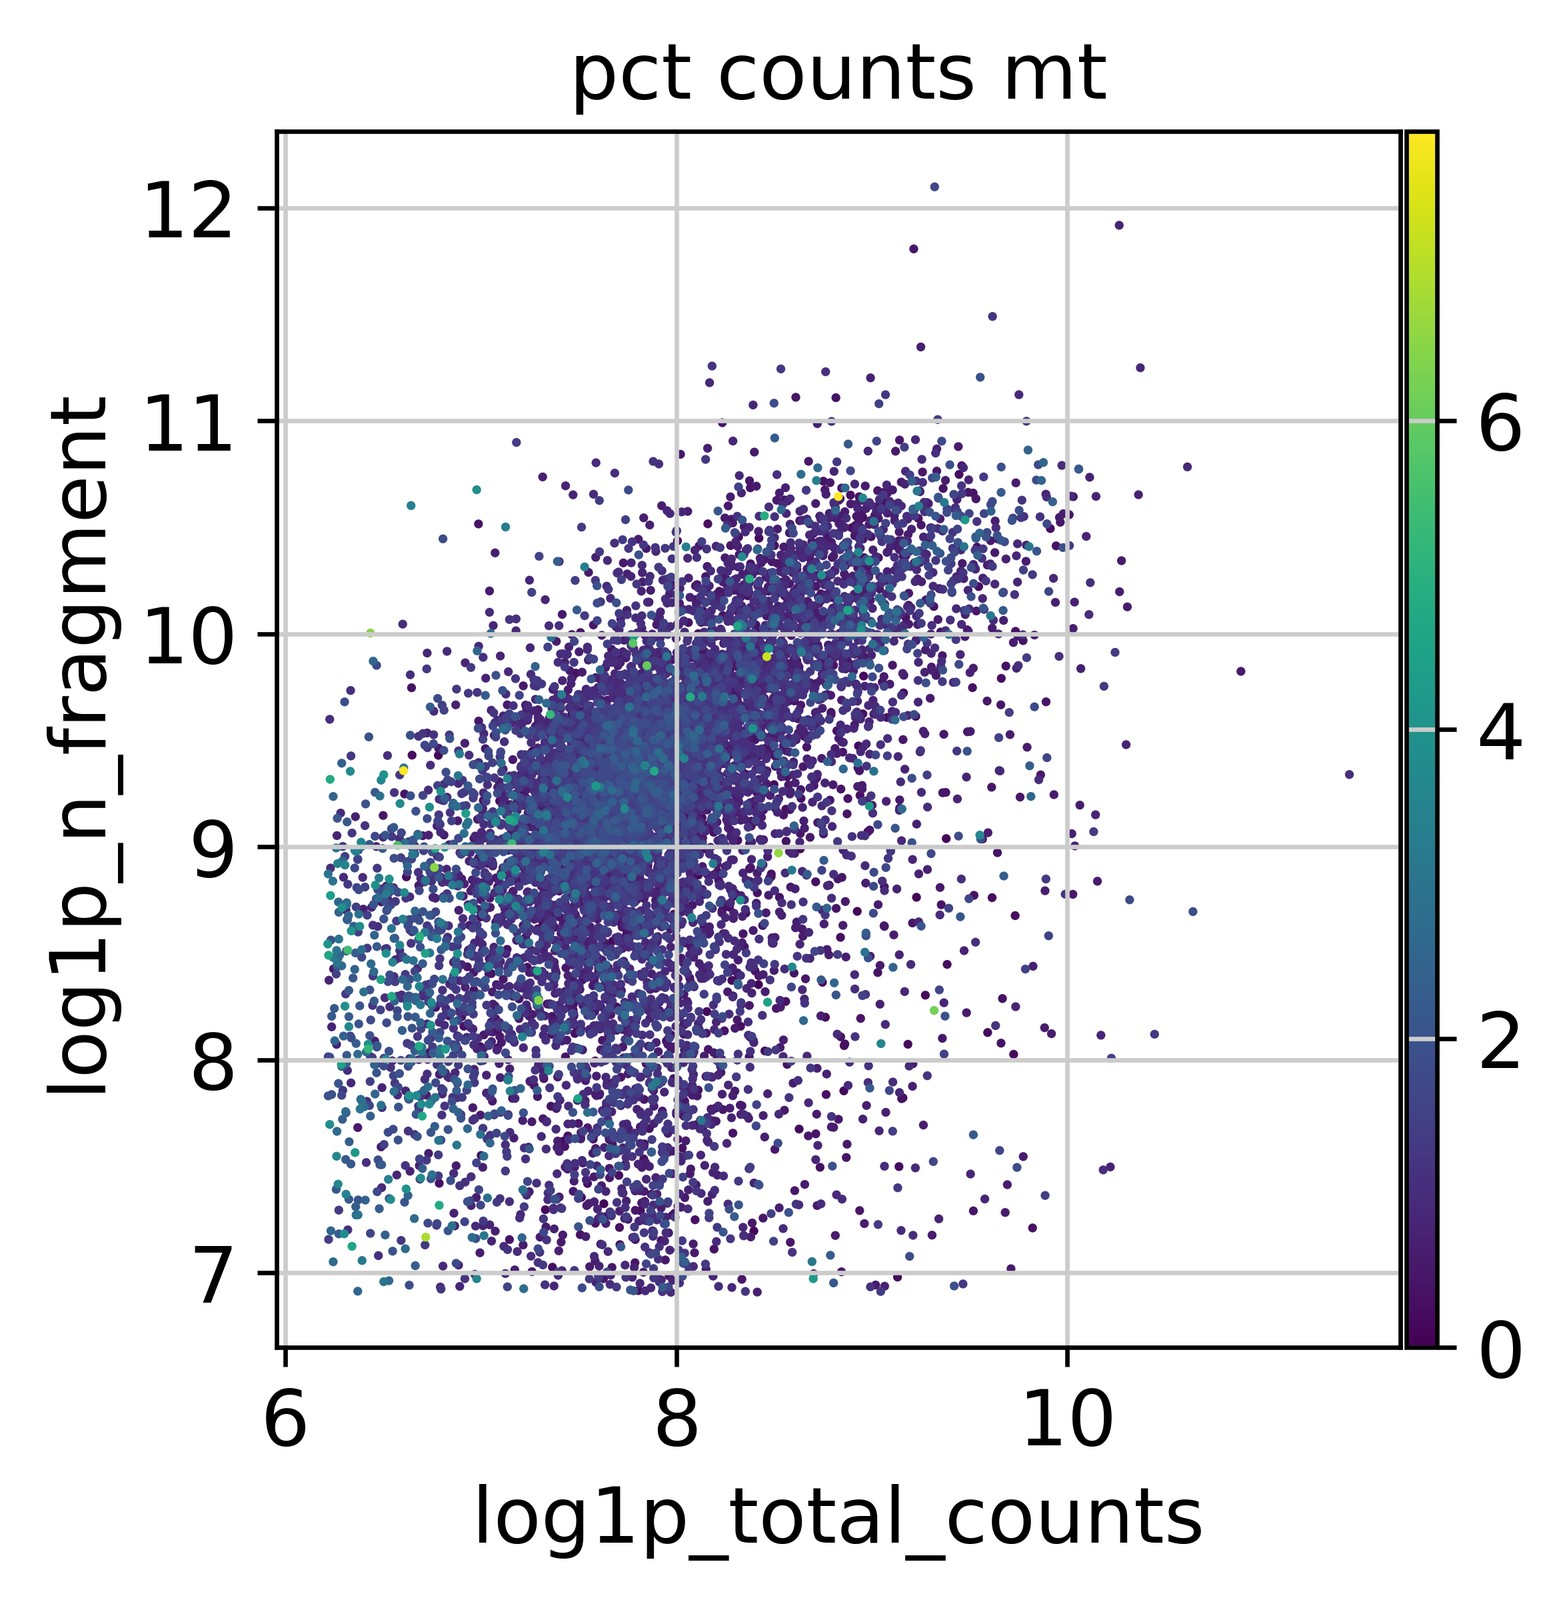

In [29]:
sc.pl.scatter(adata, "log1p_total_counts", "log1p_n_fragment", color="pct_counts_mt")

In [30]:
normalise_and_cluster(adata)

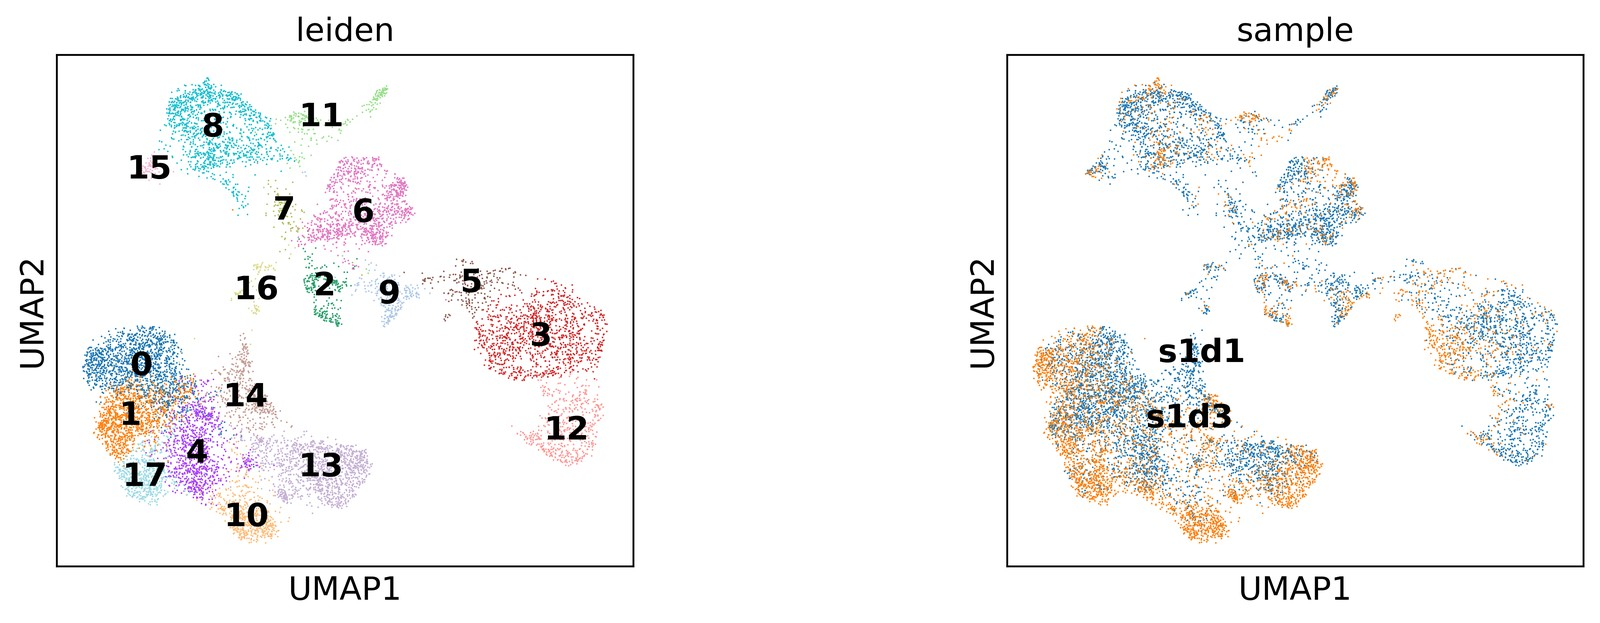

In [31]:
sc.pl.umap(adata, color=["leiden", "sample"], legend_loc="on data", wspace=0.5, size=2)

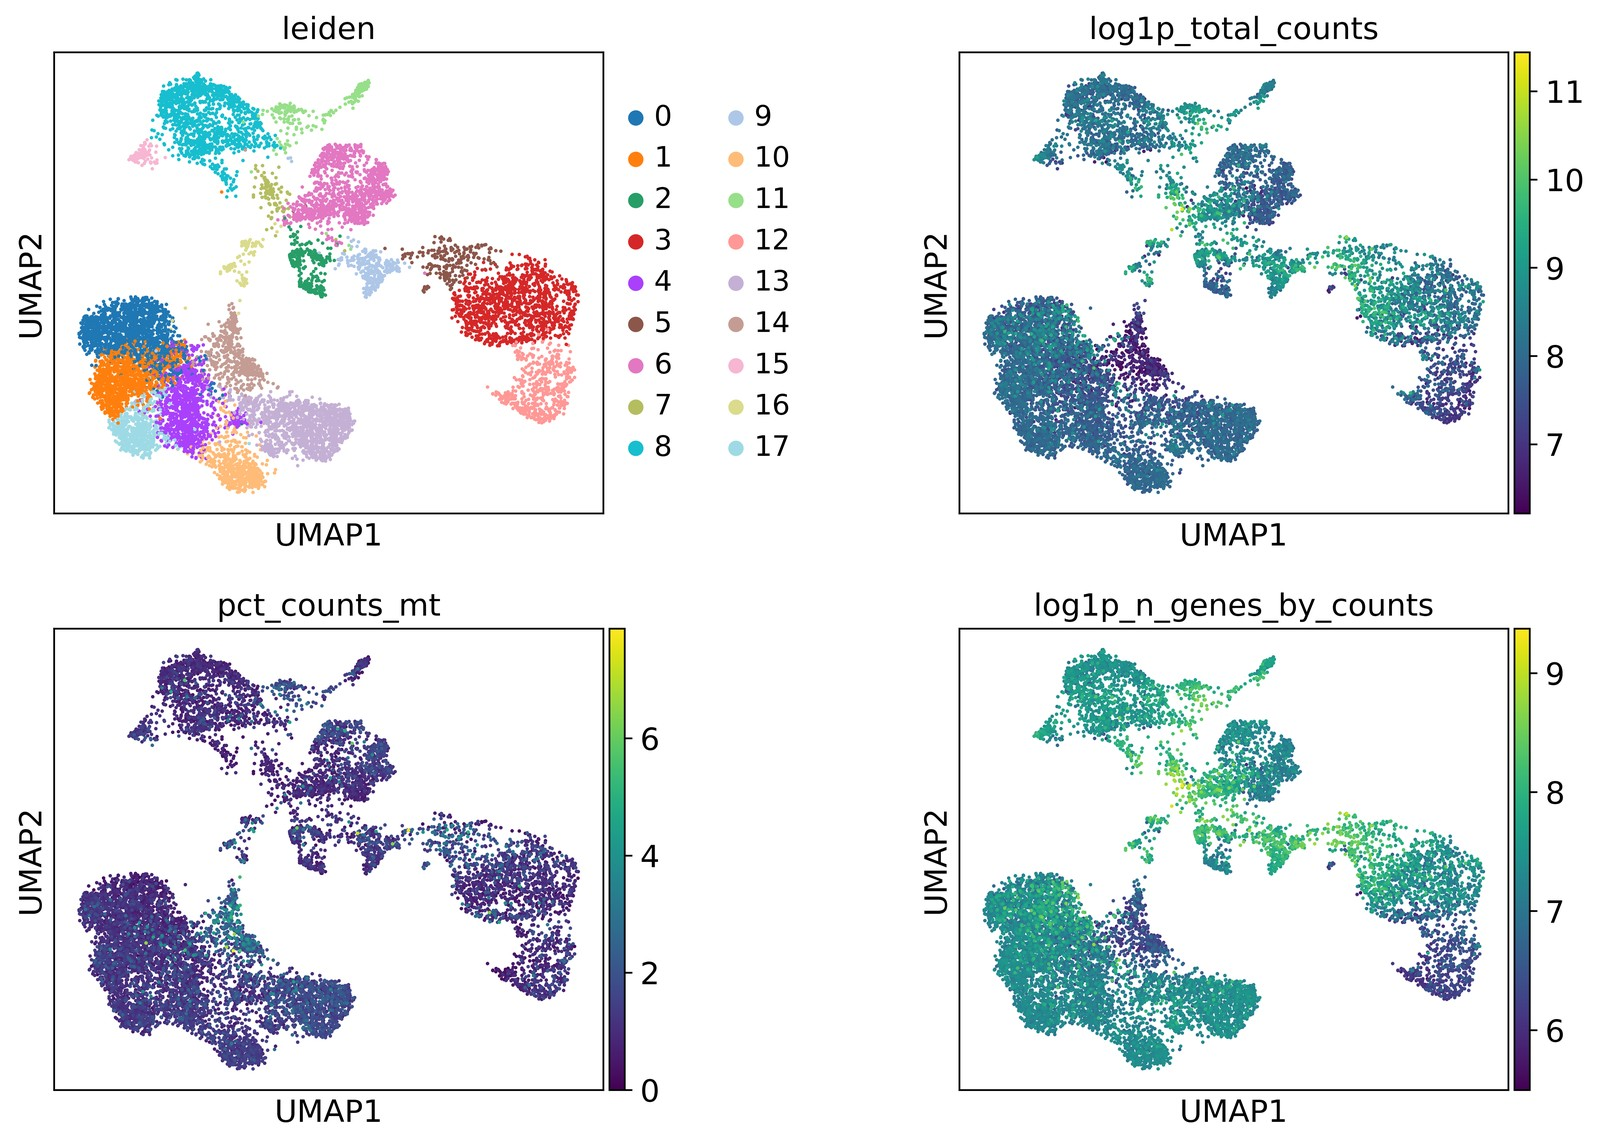

In [32]:
sc.pl.umap(
    adata,
    color=["leiden", "log1p_total_counts", "pct_counts_mt", "log1p_n_genes_by_counts"],
    wspace=0.5,
    ncols=2,
)

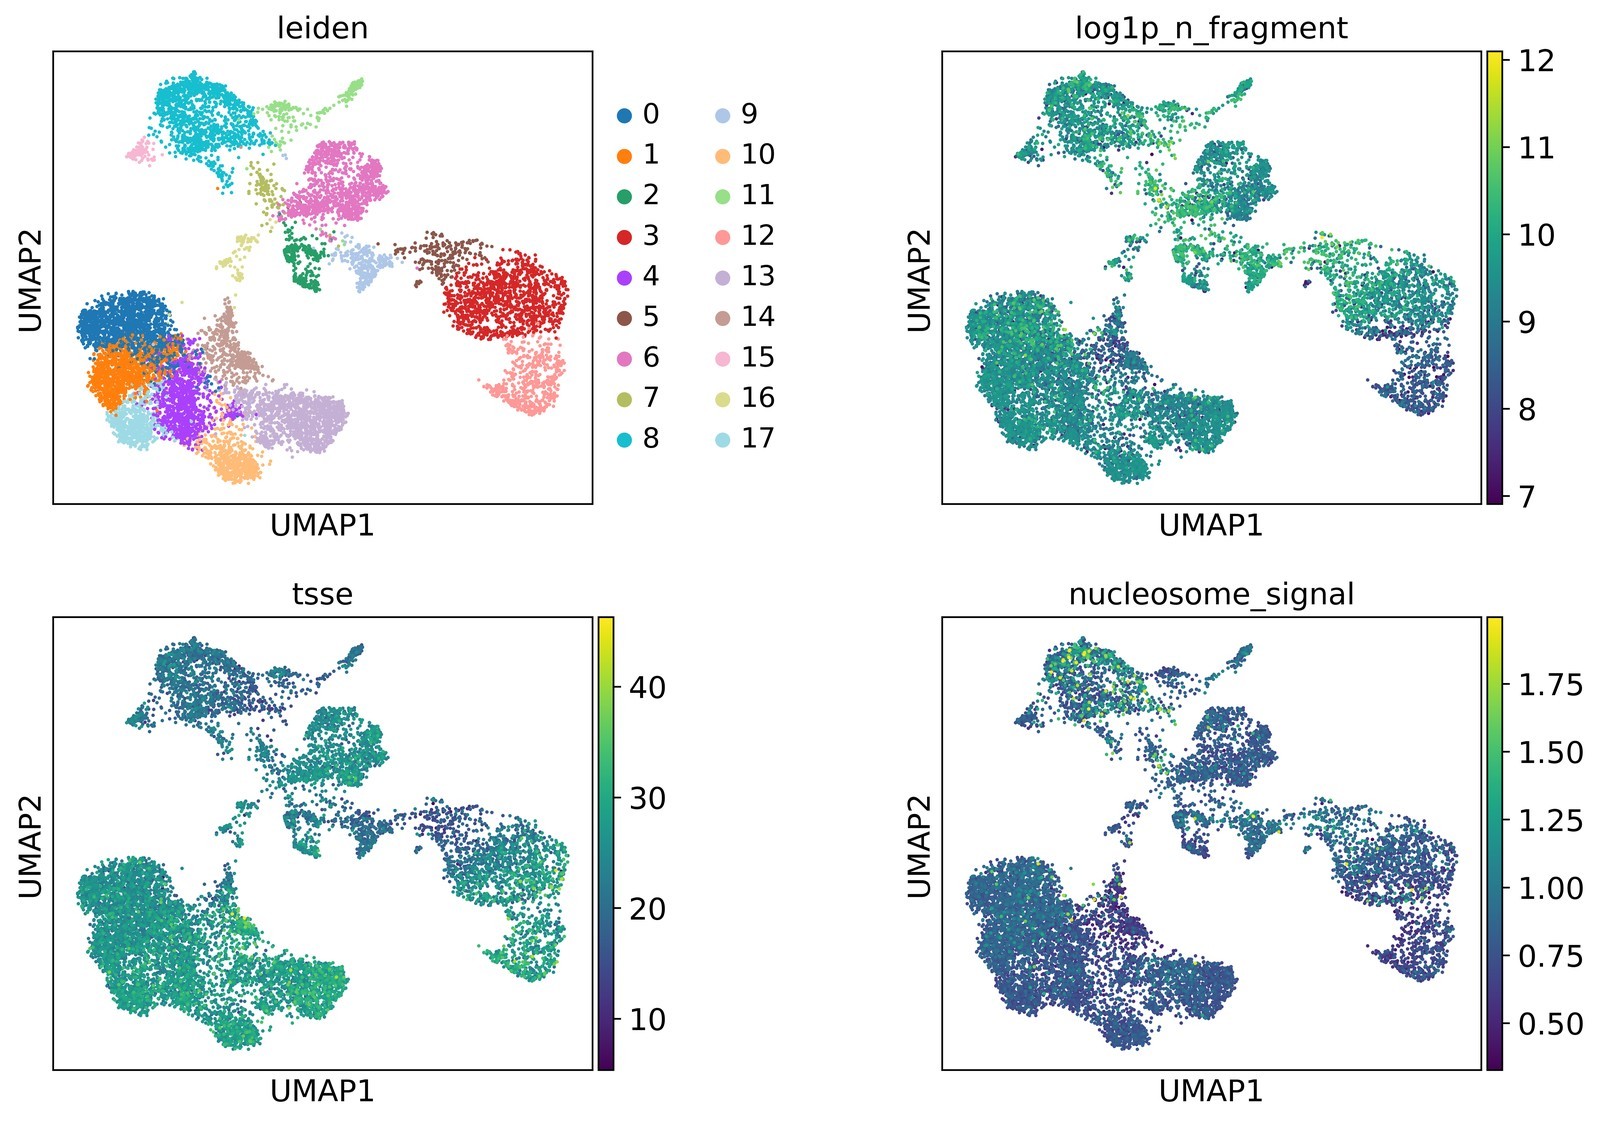

In [33]:
sc.pl.umap(
    adata,
    color=["leiden", "log1p_n_fragment", "tsse", "nucleosome_signal"],
    wspace=0.5,
    ncols=2,
)

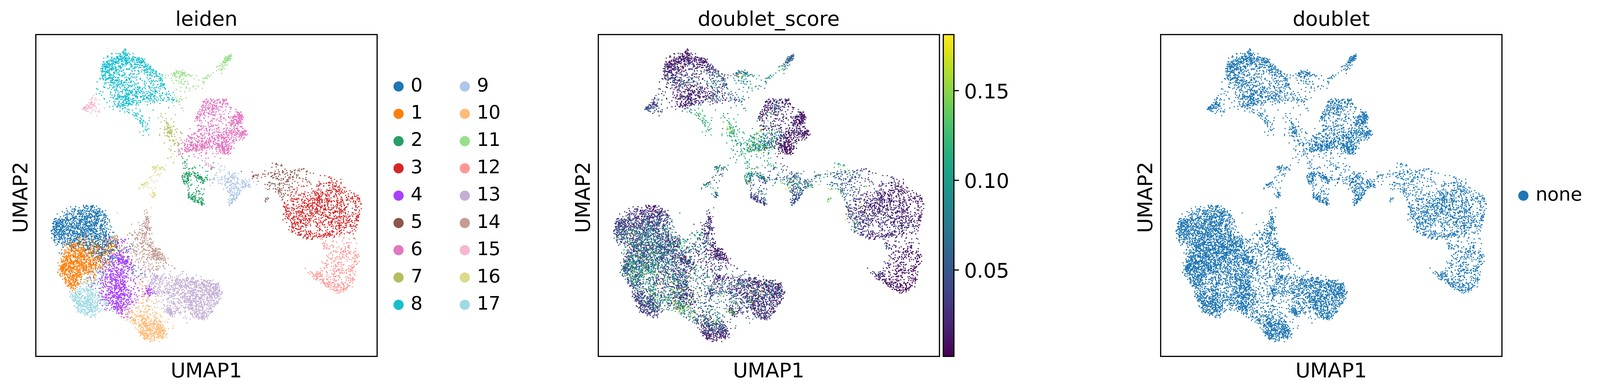

In [34]:
sc.pl.umap(
    adata,
    color=["leiden", "doublet_score", "doublet"],
    wspace=0.5,
    size=3,
)

### Final filtering

The thresholds from the first filtering, plus upper limits on RNA counts and ATAC fragments to remove
remaining potential doublets. Preview, adjust, then apply.

In [35]:
checks = pd.DataFrame({
    "RNA: genes >= 100": adata.obs["n_genes_by_counts"] >= 100,
    "RNA: counts 500-25,000": adata.obs["total_counts"].between(500, 25_000),
    "RNA: mito <= 10%": adata.obs["pct_counts_mt"] <= 10,
    "ATAC: fragments <= 100,000": adata.obs["n_fragment"] <= 100_000,
    "ATAC: TSSE >= 5": adata.obs["tsse"] >= 5,
    "ATAC: nucleosome signal < 2": adata.obs["nucleosome_signal"] < 2,
})

summary = pd.DataFrame({
    "fail": (~checks).sum(),
    "fail only this check": {c: (~checks[c] & checks.drop(columns=c).all(axis=1)).sum() for c in checks},
})
print(summary.to_string())

keep = checks.all(axis=1)
print(f"\nWould remove {(~keep).sum()} of {len(keep)} cells ({(~keep).mean():.1%}), keeping {keep.sum()}")

adata.obs["qc"] = pd.Categorical(np.where(keep, "keep", "remove"))
print(pd.crosstab(adata.obs["sample"], adata.obs["qc"]).to_string())

                             fail  fail only this check
RNA: genes >= 100               0                     0
RNA: counts 500-25,000         23                    22
RNA: mito <= 10%                0                     0
ATAC: fragments <= 100,000      3                     2
ATAC: TSSE >= 5                 0                     0
ATAC: nucleosome signal < 2     0                     0

Would remove 25 of 11701 cells (0.2%), keeping 11676
qc      keep  remove
sample              
s1d1    6961      11
s1d3    4715      14


In [36]:
# share of each cluster failing each check
by_cluster = (~checks).groupby(adata.obs["leiden"], observed=True).mean().round(2)
by_cluster.insert(0, "cells", adata.obs["leiden"].value_counts())
by_cluster

,cells,RNA: genes >= 100,"RNA: counts 500-25,000",RNA: mito <= 10%,"ATAC: fragments <= 100,000",ATAC: TSSE >= 5,ATAC: nucleosome signal < 2
leiden,,,,,,,
0,1473,0.0,0.00,0.0,0.00,0.0,0.0
1,1197,0.0,0.00,0.0,0.00,0.0,0.0
2,251,0.0,0.00,0.0,0.00,0.0,0.0
3,1157,0.0,0.00,0.0,0.00,0.0,0.0
4,982,0.0,0.00,0.0,0.00,0.0,0.0
5,211,0.0,0.03,0.0,0.00,0.0,0.0
6,1116,0.0,0.00,0.0,0.00,0.0,0.0
7,101,0.0,0.11,0.0,0.02,0.0,0.0
8,1219,0.0,0.00,0.0,0.00,0.0,0.0


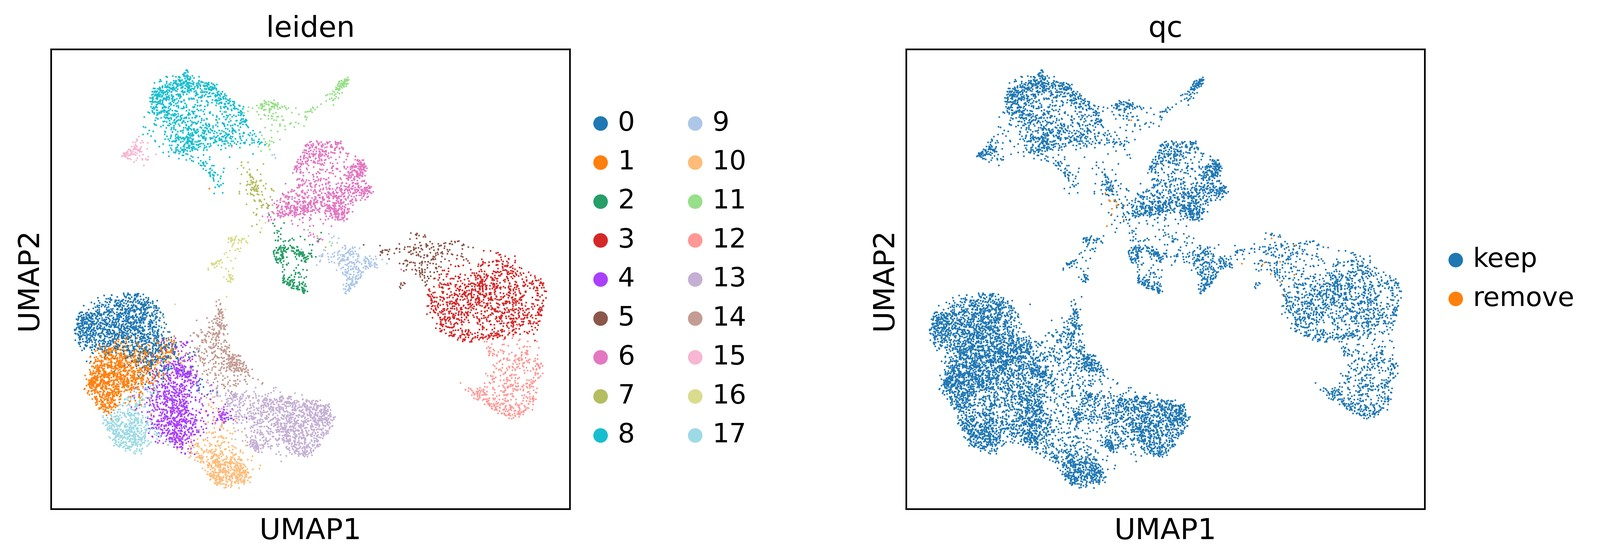

In [37]:
sc.pl.umap(adata, color=["leiden", "qc"], wspace=0.5, size=3)

### Apply the final filter

Removes the cells failing any check, then genes detected in fewer than 3 of the remaining cells, so the
saved gene set is defined by the final cells.

In [38]:
adata = adata[keep].copy()
sc.pp.filter_genes(adata, min_cells=3)
adata

AnnData object with n_obs × n_vars = 11676 × 26150
    obs: 'sample', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'n_fragment', 'tsse', 'nucleosome_signal', 'log1p_n_fragment', 'n_genes', 'doublet_score', 'predicted_doublet', 'amulet_q', 'amulet_multiplet', 'doublet', 'leiden', 'qc'
    var: 'gene_ids', 'feature_types', 'genome', 'interval', 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'scrublet', 'hvg', 'pca', 'neighbors', 'umap', 'leiden', 'leiden_colors', 'sampl

## Final clustering

Normalization, feature selection, dimensionality reduction, neighbours, UMAP and clustering as in the
tutorial, now on the filtered cells, using the same function as the exploratory clustering.

In [39]:
normalise_and_cluster(adata)

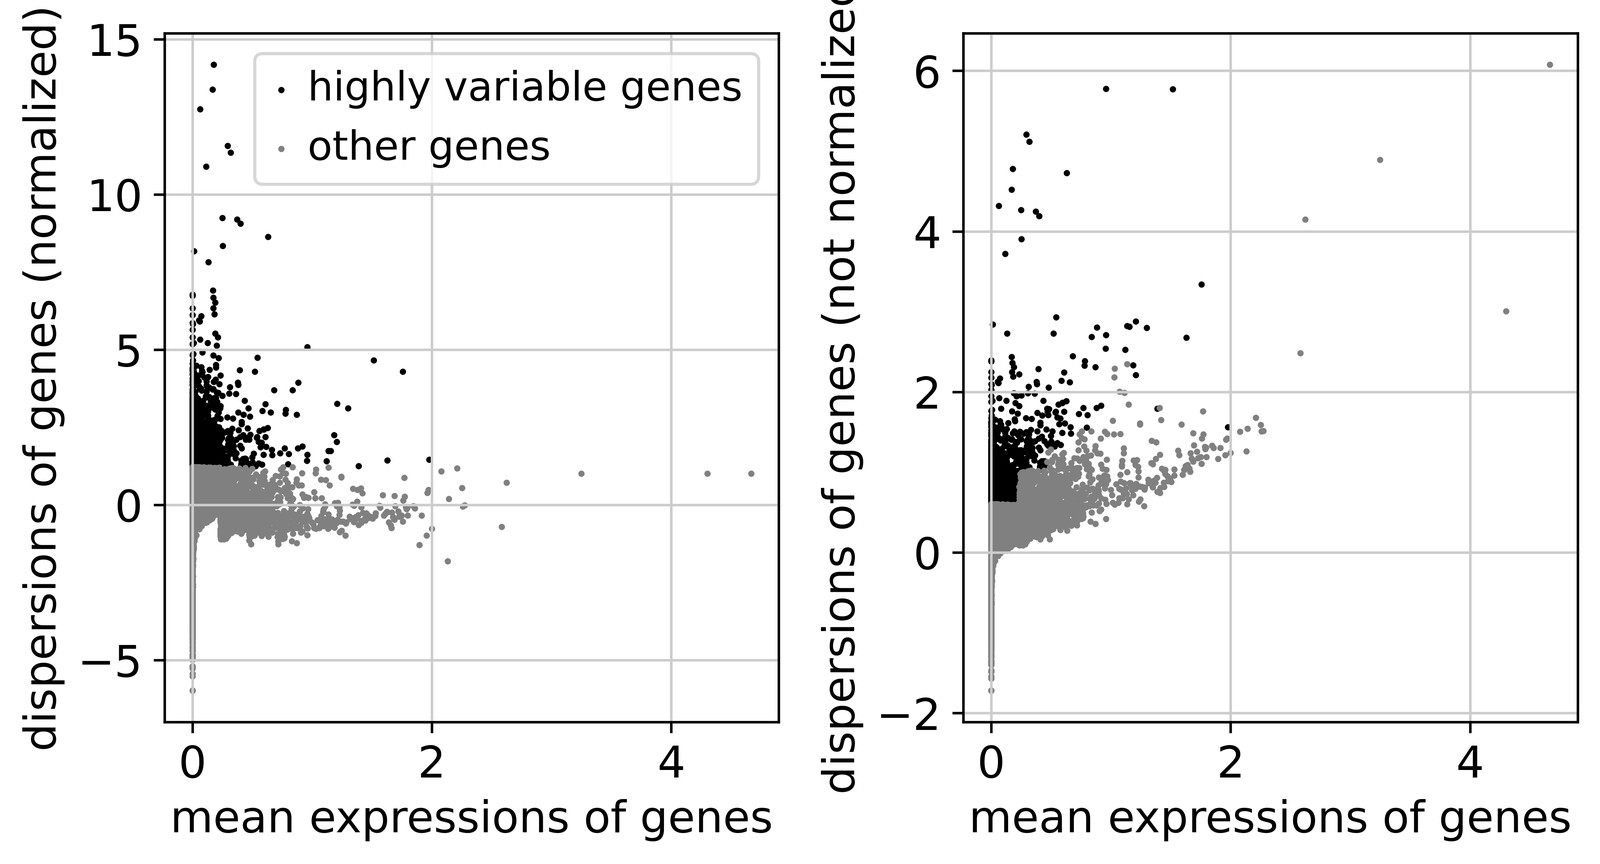

In [40]:
sc.pl.highly_variable_genes(adata)

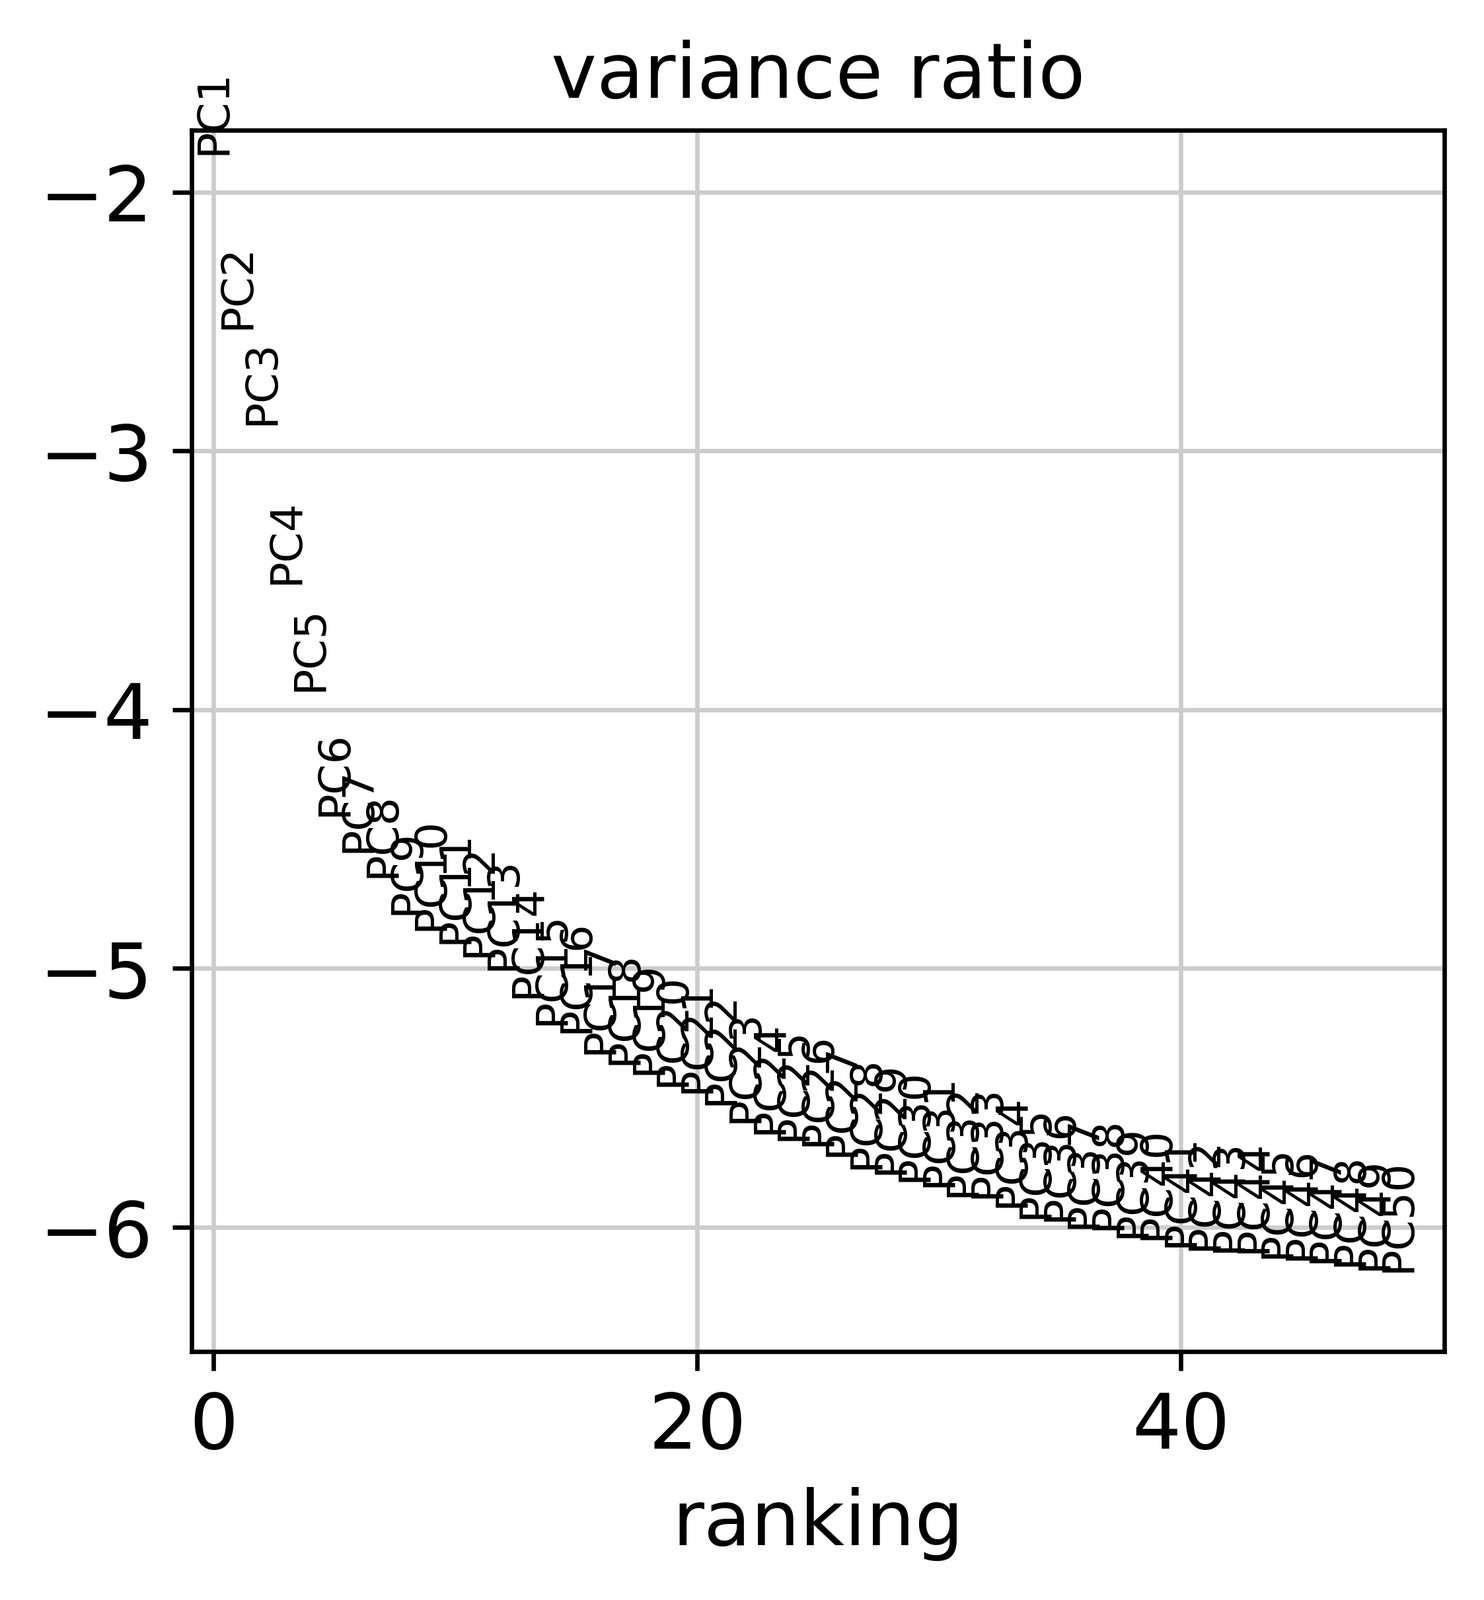

In [41]:
sc.pl.pca_variance_ratio(adata, n_pcs=50, log=True)

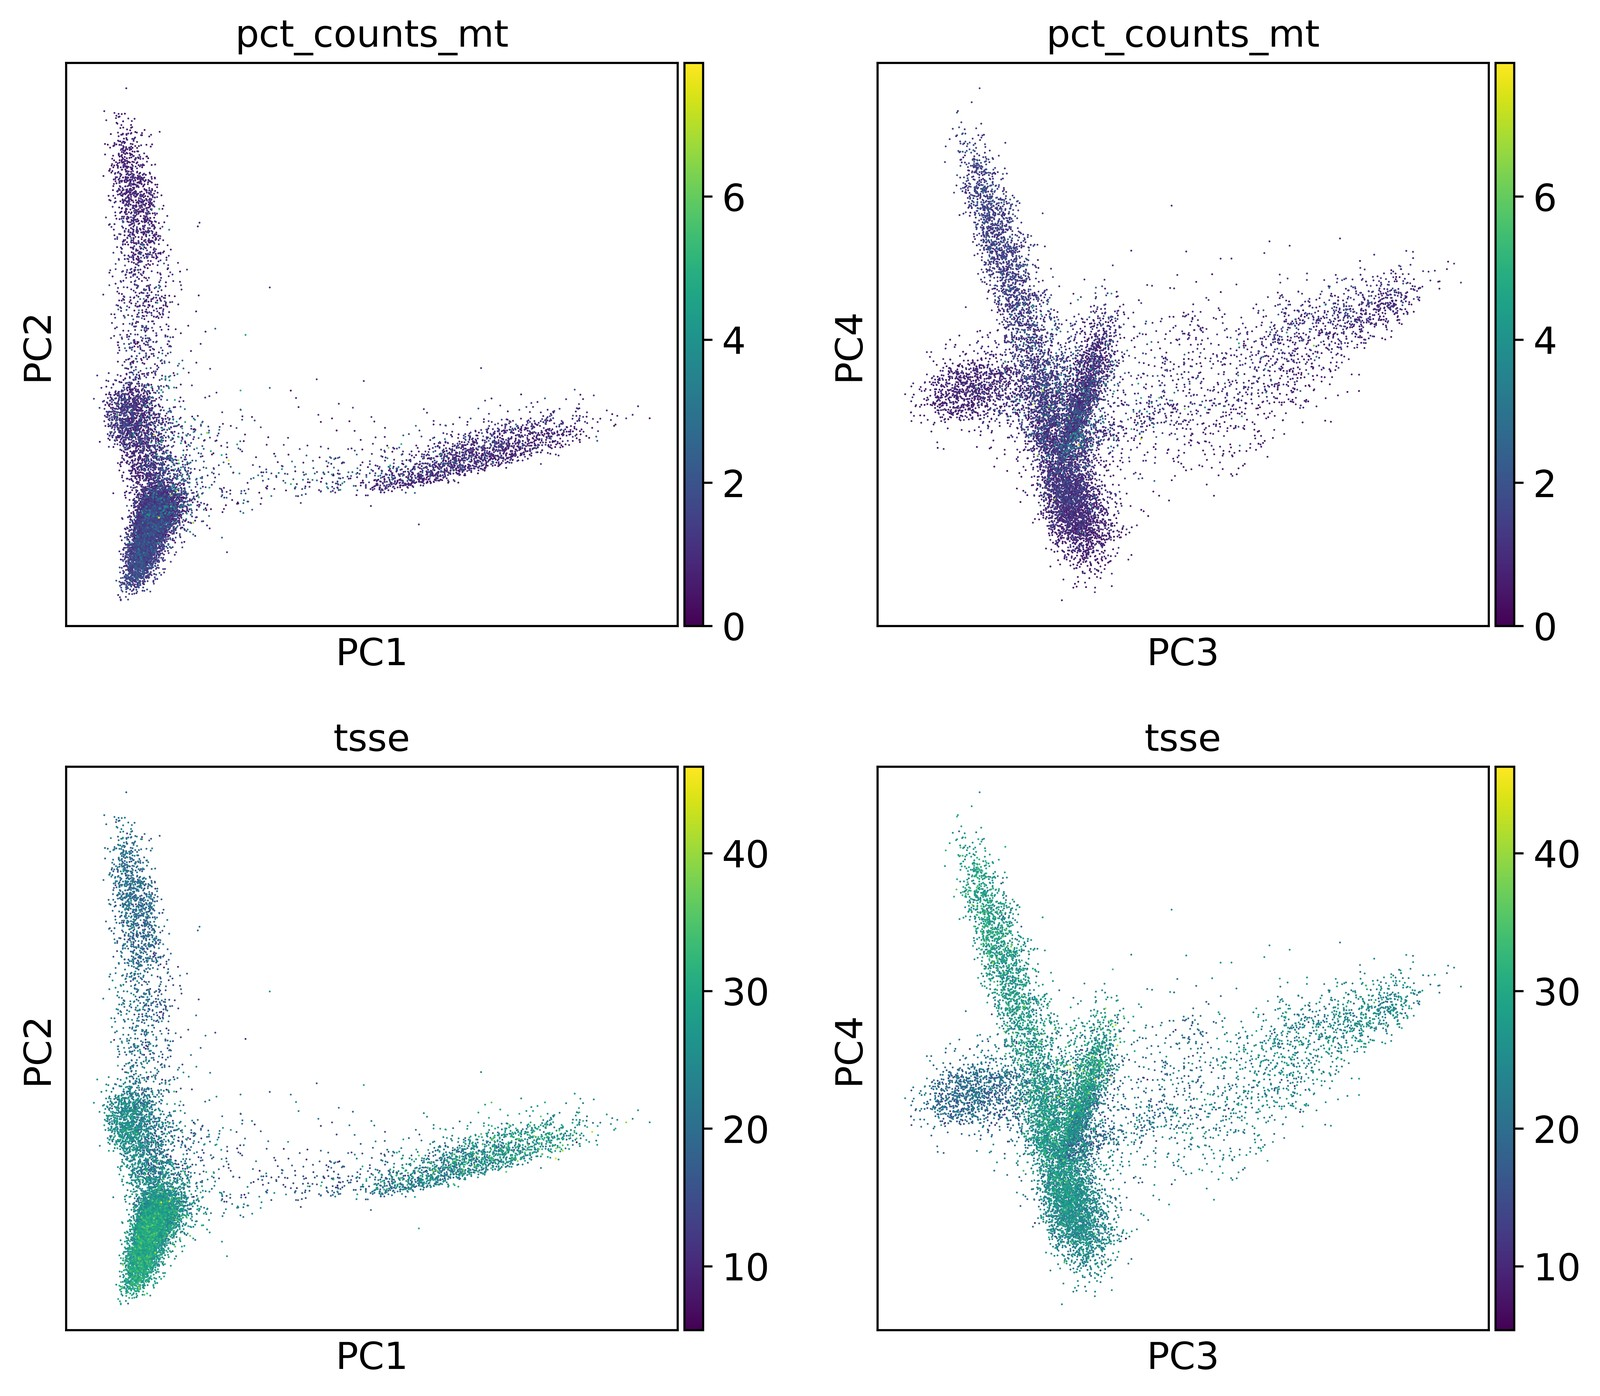

In [42]:
sc.pl.pca(
    adata,
    color=["pct_counts_mt", "pct_counts_mt", "tsse", "tsse"],
    dimensions=[(0, 1), (2, 3), (0, 1), (2, 3)],
    ncols=2,
    size=2,
)

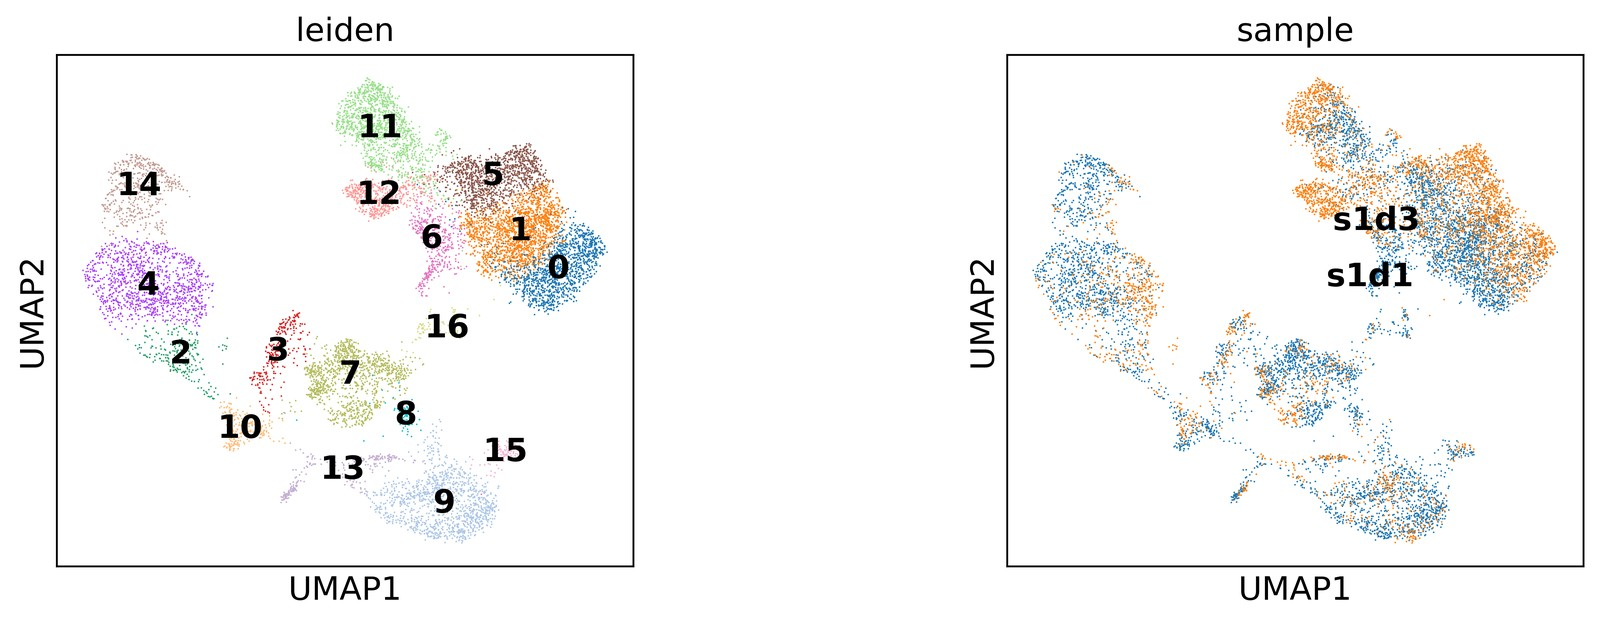

In [43]:
sc.pl.umap(adata, color=["leiden", "sample"], legend_loc="on data", wspace=0.5, size=2)

Final check: no cluster should still be defined by a QC metric or doublet score. If one is, go back to
**Final filtering**.

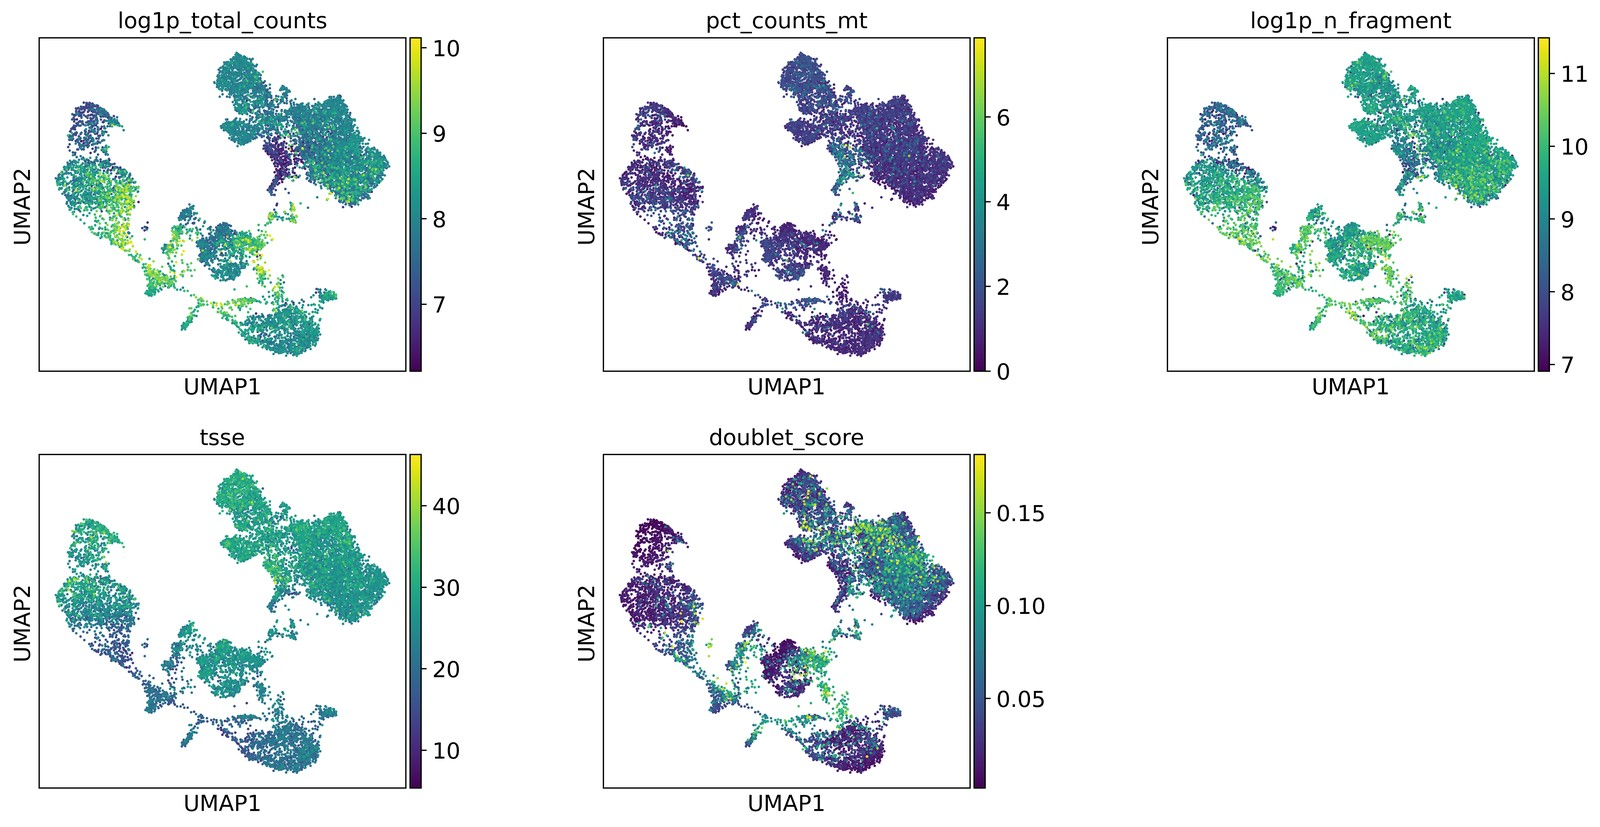

In [44]:
sc.pl.umap(
    adata,
    color=["log1p_total_counts", "pct_counts_mt", "log1p_n_fragment", "tsse", "doublet_score"],
    ncols=3,
    wspace=0.4,
)

## Cell-type annotation with Azimuth

[Azimuth](https://azimuth.hubmapconsortium.org/), run from Python with
[azimuthpy](https://github.com/KalinNonchev/azimuthpy), maps each cell onto an annotated reference and
transfers its labels. Here the reference is the Azimuth **human PBMC** reference (Hao et al. 2021), at its `celltype.l1` level (broad types: B, CD4 T, CD8 T, other T, NK, Mono, DC, other). The reference also has the finer `celltype.l2` and `celltype.l3` levels, which Azimuth predicts too.

Azimuth normalises the raw counts itself, so it is given `adata.layers["counts"]` of the final cells.
It adds to `adata.obs`, per cell:

- `predicted.celltype.l1`: the predicted label.
- `predicted.celltype.l1.score`: confidence in that label, from 0 to 1.
- `mapping.score`: how well the cell is represented in the reference, from 0 to 1. Low values mean
  the cell doesn't resemble anything in the reference.

and the cells' positions on the reference UMAP in `adata.obsm["ref.umap"]`. The reference files were
downloaded by `jobs/05_create_env_azimuth.sbatch`.

Bone marrow has populations PBMC does not, such as HSPCs, erythroid and myeloid progenitors, and plasma cells. The
PBMC reference has no matching classes for them, so expect them to map to `other` or to the nearest blood type,
with lower scores. Downstream comparisons with PBMC use only the six mature types (Mono, CD4 T, CD8 T, B, NK, DC).

In [45]:
# azimuthpy reads layers["raw_counts"] whatever use_layer says, so point it at the counts
adata.layers["raw_counts"] = adata.layers["counts"]
adata = annotate_adata_azimuth(adata, reference_path=str(azimuth_ref), use_layer="raw_counts")
del adata.layers["raw_counts"]

R[write to console]: Warning:


R[write to console]:  Data is of class matrix. Coercing to dgCMatrix.



R[write to console]: Warning:


R[write to console]:  Overwriting miscellanous data for model



R[write to console]: Warning:


...

R[write to console]: *


R[write to console]: *


R[write to console]: *


R[write to console]: |



R[write to console]: Total elapsed time: 7.87907266616821



In [46]:
label = "predicted.celltype.l1"
adata.obs[label] = adata.obs[label].astype("category")

adata.obs.groupby(label, observed=True).agg(
    cells=(label, "size"),
    median_prediction_score=(f"{label}.score", "median"),
    median_mapping_score=("mapping.score", "median"),
).round(2)

,cells,median_prediction_score,median_mapping_score
predicted.celltype.l1,,,
B,1241,1.00,0.75
CD4 T,2891,0.83,0.60
CD8 T,2140,0.74,0.71
DC,167,0.98,0.99
Mono,1297,0.77,0.62
NK,1688,0.99,0.67
other,1560,0.90,0.60
other T,692,0.81,0.77


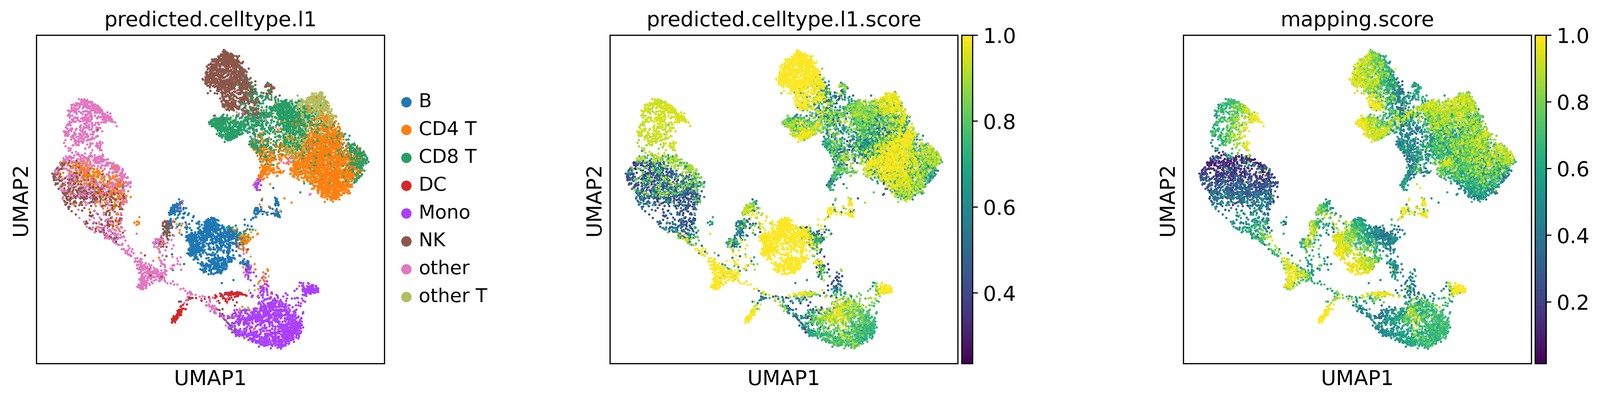

In [47]:
sc.pl.umap(adata, color=[label, f"{label}.score", "mapping.score"], wspace=0.5)

The same cells placed on the reference's UMAP:

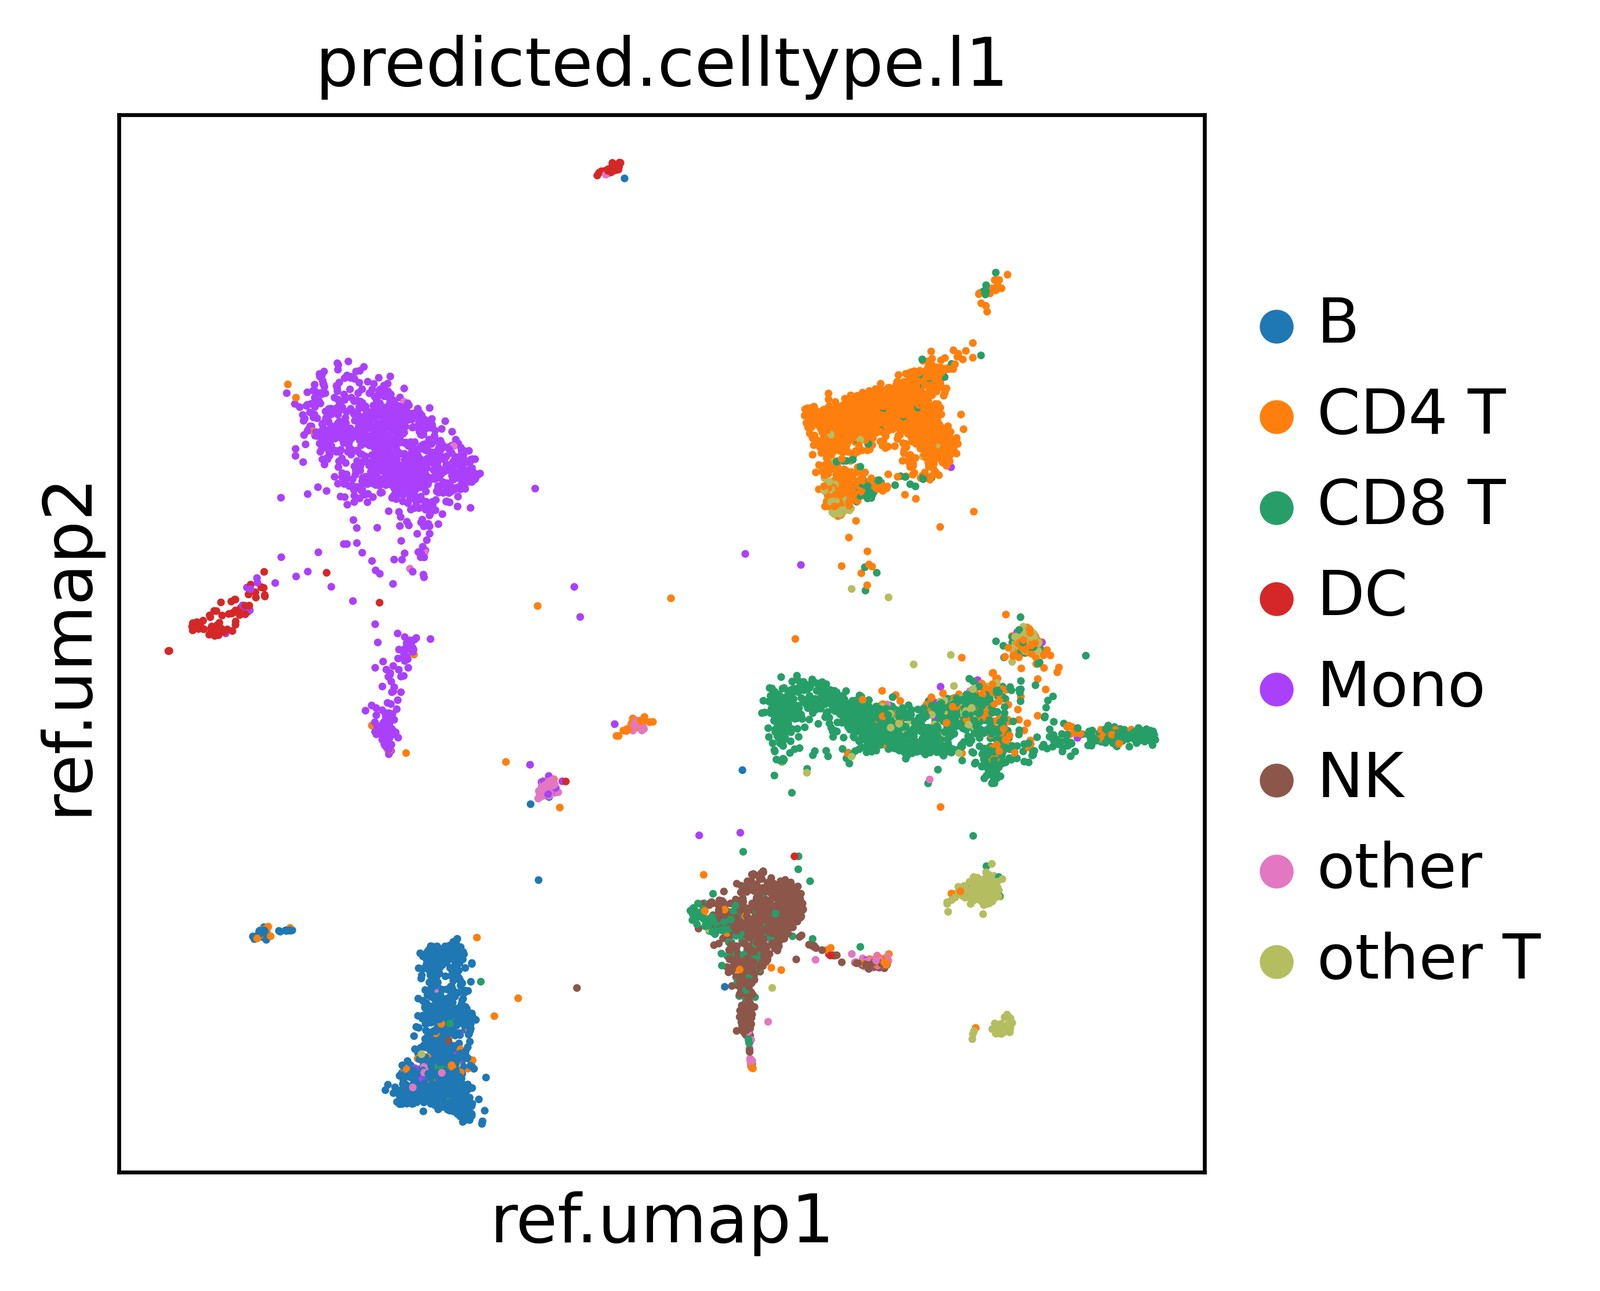

In [48]:
sc.pl.embedding(adata, basis="ref.umap", color=label)

Predicted labels per Leiden cluster. A cluster split across several labels, or a label spread across
many clusters, is worth checking against marker genes.

In [49]:
pd.crosstab(adata.obs["leiden"], adata.obs[label])

predicted.celltype.l1,B,CD4 T,CD8 T,DC,Mono,NK,other,other T
leiden,,,,,,,,
0,0,868,378,1,0,0,2,43
1,0,1266,270,0,0,2,11,179
2,1,29,0,0,0,63,130,0
3,103,14,4,0,0,68,65,3
4,4,279,0,0,0,330,525,0
5,0,90,657,0,0,3,1,425
6,1,246,171,0,21,5,11,2
7,1008,58,16,0,0,6,19,19
8,34,4,0,1,22,3,9,2


### Assign cell types

`cell_type` is the Azimuth label, except that cells with a prediction score below `MIN_SCORE` are
labelled "low confidence". Choose `MIN_SCORE` from the score plots above.

In [50]:
MIN_SCORE = 0

confident = adata.obs[f"{label}.score"] >= MIN_SCORE
adata.obs["cell_type"] = adata.obs[label].astype(str).where(confident, "low confidence").astype("category")
adata.obs["cell_type"].value_counts()

cell_type
CD4 T      2891
CD8 T      2140
NK         1688
other      1560
Mono       1297
B          1241
other T     692
DC          167
Name: count, dtype: int64

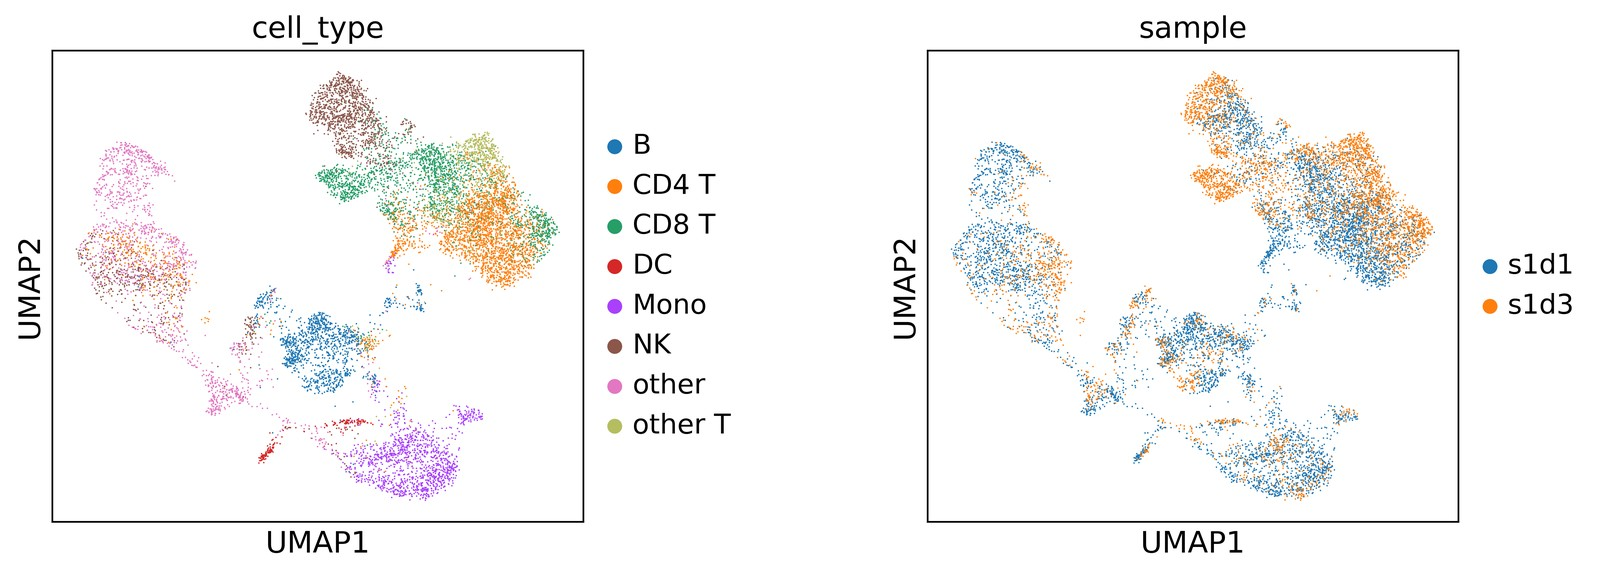

In [51]:
sc.pl.umap(adata, color=["cell_type", "sample"], wspace=0.5, size=2)

## Highly variable gene flags

Two flags, one row per gene kept after filtering:

- `hvg_clustering`: the 2,000 genes used for PCA, neighbours and clustering above.
- `hvg_eval`: scanpy's default HVG selection (fixed mean and dispersion cut-offs, so the
  number varies by dataset). Use this one to evaluate models.

Both are computed on the log-normalised expression of the final cells. Gene symbols can be
duplicated, so join on `gene_id` downstream.

In [52]:
hvg_defaults = sc.pp.highly_variable_genes(adata, inplace=False)
adata.var["hvg_eval"] = hvg_defaults["highly_variable"]

genes = pd.DataFrame({
    "gene_id": adata.var["gene_ids"],
    "n_cells": adata.var["n_cells"],
    "hvg_clustering": adata.var["highly_variable"],
    "hvg_eval": adata.var["hvg_eval"],
}).rename_axis("gene_symbol")
genes.to_csv(out_dir / "genes.tsv", sep="\t")
genes[["hvg_clustering", "hvg_eval"]].sum()

hvg_clustering    2000
hvg_eval          3181
dtype: int64

## Save

The final cells with QC metrics, doublet calls, sample, clusters, Azimuth predictions and HVG flags. There is no
ATAC peak matrix for BMMC; ATAC analyses use the fragment files directly.

In [53]:
adata.write_h5ad(out_dir / "rna_annotated.h5ad")

## Check the saved files

Reads the saved files back and stops with an error if any check fails: the same cells as the final
`adata`, a cell-type label and scores for every cell, and both HVG flags for every gene,
matching `genes.tsv`.

In [54]:
# Read the saved files back and compare them with the final adata
rna_saved = sc.read_h5ad(out_dir / "rna_annotated.h5ad", backed="r")
genes_saved = pd.read_csv(out_dir / "genes.tsv", sep="\t", index_col="gene_symbol")

# cells: same cells as the final adata, in the same order, with a sample for each
assert rna_saved.shape == adata.shape, (rna_saved.shape, adata.shape)
assert (rna_saved.obs_names == adata.obs_names).all()
assert rna_saved.obs_names.is_unique
assert rna_saved.obs["sample"].notna().all()

# cell-type labels: present for every cell
for col in ["cell_type", label, f"{label}.score", "mapping.score"]:
    assert col in rna_saved.obs and rna_saved.obs[col].notna().all(), col
assert "ref.umap" in rna_saved.obsm

# HVG flags: a True/False flag for every gene, and genes.tsv matches the h5ad
for col in ["highly_variable", "hvg_eval"]:
    assert rna_saved.var[col].dtype == bool, col
assert (genes_saved.index == rna_saved.var_names).all()
assert (genes_saved["hvg_clustering"].to_numpy() == rna_saved.var["highly_variable"].to_numpy()).all()
assert (genes_saved["hvg_eval"].to_numpy() == rna_saved.var["hvg_eval"].to_numpy()).all()
assert genes_saved["gene_id"].is_unique

print(f"{rna_saved.n_obs:,} cells, {rna_saved.n_vars:,} genes (RNA)")
print(f"HVGs: {int(genes_saved['hvg_clustering'].sum()):,} for clustering, "
      f"{int(genes_saved['hvg_eval'].sum()):,} for evaluation")
rna_saved.file.close()
pd.crosstab(rna_saved.obs["cell_type"], rna_saved.obs["sample"], margins=True)

11,676 cells, 26,150 genes (RNA)
HVGs: 2,000 for clustering, 3,181 for evaluation


sample,s1d1,s1d3,All
cell_type,,,
B,929,312,1241
CD4 T,1795,1096,2891
CD8 T,920,1220,2140
DC,101,66,167
Mono,1014,283,1297
NK,838,850,1688
other,1136,424,1560
other T,228,464,692
All,6961,4715,11676
